In [274]:
import pandas as pd

In [275]:
import pandas as pd
import numpy as np

# 1. Load NHANES Data components
demo = pd.read_sas('/content/DEMO_L.xpt', format='xport')
mcq = pd.read_sas('/content/MCQ_L.xpt', format='xport')
food = pd.read_sas('/content/FSQ_L.xpt', format='xport')
insurance = pd.read_sas('/content/HIQ_L.xpt', format='xport')
access = pd.read_sas('/content/HUQ_L.xpt', format='xport')
bp = pd.read_sas('/content/BPQ_L.xpt', format='xport')
diabetes = pd.read_sas('/content/DIQ_L.xpt', format='xport')
smoking = pd.read_sas('/content/SMQ_L.xpt', format='xport')
physical_act = pd.read_sas('/content/PAQ_L.xpt', format='xport')
body = pd.read_sas('/content/BMX_L.xpt', format='xport')
hdl = pd.read_sas('/content/HDL_L.xpt', format='xport')
tchol = pd.read_sas('/content/TCHOL_L.xpt', format='xport')

print('Raw files loaded successfully!')

Raw files loaded successfully!


In [276]:
# 2. Clean and Construct the Primary Outcome (Heart Disease Composite Variable)
heart_vars = ['MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E']
mcq[heart_vars] = mcq[heart_vars].replace({7: np.nan, 9: np.nan})

def define_heart_disease(row):
    vals = row[heart_vars]
    if (vals == 1).any():
        return 1
    elif (vals == 2).all():
        return 0
    return np.nan

mcq['heart_disease'] = mcq.apply(define_heart_disease, axis=1)
print('Composite Heart Disease Outcome Count:')
print(mcq['heart_disease'].value_counts(dropna=False))

Composite Heart Disease Outcome Count:
heart_disease
0.0    7025
NaN    3974
1.0     745
Name: count, dtype: int64


In [277]:
# 3. Consolidate demographic, social determinants of health, risk factors, and clinical labs
working_df = demo[['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'DMDMARTZ', 'DMDHHSIZ', 'INDFMPIR', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU']].copy()

# Process and Merge MCQ Outcome
working_df = working_df.merge(mcq[['SEQN', 'heart_disease']], on='SEQN', how='inner')
working_df = working_df[working_df['heart_disease'].notna()].copy()

# Merge Food Security
working_df = working_df.merge(food[['SEQN', 'FSDAD']], on='SEQN', how='left')

# Merge Insurance & Access to Care
working_df = working_df.merge(insurance[['SEQN', 'HIQ011']], on='SEQN', how='left')
working_df = working_df.merge(access[['SEQN', 'HUQ030']], on='SEQN', how='left')

# Merge Risk Factors
working_df = working_df.merge(bp[['SEQN', 'BPQ020']], on='SEQN', how='left')
working_df = working_df.merge(diabetes[['SEQN', 'DIQ010']], on='SEQN', how='left')

# Merge Smoking
smoking['smoking_status'] = np.nan
smoking.loc[smoking['SMQ020'] == 2, 'smoking_status'] = 0
smoking.loc[(smoking['SMQ020'] == 1) & (smoking['SMQ040'] == 3), 'smoking_status'] = 1
smoking.loc[(smoking['SMQ020'] == 1) & (smoking['SMQ040'].isin([1, 2])), 'smoking_status'] = 2
working_df = working_df.merge(smoking[['SEQN', 'smoking_status']], on='SEQN', how='left')

# Merge Physical Activity
physical_act['sedentary_minutes'] = physical_act['PAD680'].replace({7777: np.nan, 9999: np.nan})
physical_act.loc[physical_act['sedentary_minutes'] < 1, 'sedentary_minutes'] = 0
working_df = working_df.merge(physical_act[['SEQN', 'sedentary_minutes']], on='SEQN', how='left')

# Merge Clinical Measures
working_df = working_df.merge(body[['SEQN', 'BMXBMI']], on='SEQN', how='left')
working_df = working_df.merge(hdl[['SEQN', 'LBDHDD']], on='SEQN', how='left')
working_df = working_df.merge(tchol[['SEQN', 'LBXTC']], on='SEQN', how='left')

print('Initial Merged Dataset Shape:', working_df.shape)

Initial Merged Dataset Shape: (7770, 23)


In [278]:
# 4. Clean Missing Codes and Perform Standard NHANES Harmonization
clean_df = working_df.copy()

clean_df['RIAGENDR'] = clean_df['RIAGENDR'].replace({7: np.nan, 9: np.nan})
clean_df['RIDRETH3'] = clean_df['RIDRETH3'].replace({7: np.nan, 9: np.nan, 77: np.nan, 99: np.nan})
clean_df['DMDEDUC2'] = clean_df['DMDEDUC2'].replace({7: np.nan, 9: np.nan})
clean_df['DMDMARTZ'] = clean_df['DMDMARTZ'].replace({77: np.nan, 99: np.nan})
clean_df['FSDAD'] = clean_df['FSDAD'].replace({7: np.nan, 9: np.nan})
clean_df['HIQ011'] = clean_df['HIQ011'].replace({7: np.nan, 9: np.nan})
clean_df['HUQ030'] = clean_df['HUQ030'].replace({7: np.nan, 9: np.nan})
clean_df['BPQ020'] = clean_df['BPQ020'].replace({7: np.nan, 9: np.nan})
clean_df['DIQ010'] = clean_df['DIQ010'].replace({7: np.nan, 9: np.nan, 3: 2}) # Group borderline with no

# Map descriptive category labels for modeling
clean_df['sex'] = clean_df['RIAGENDR'].map({1: 'Male', 2: 'Female'})
clean_df['race_ethnicity'] = clean_df['RIDRETH3'].map({1: 'Mexican American', 2: 'Other Hispanic', 3: 'Non-Hispanic White', 4: 'Non-Hispanic Black', 6: 'Non-Hispanic Asian', 7: 'Other Race/Multiracial'})
clean_df['education'] = clean_df['DMDEDUC2'].map({1: 'Less than 9th grade', 2: '9-11th grade', 3: 'High school/GED', 4: 'Some college/AA degree', 5: 'College graduate or above'})
clean_df['food_security'] = clean_df['FSDAD'].map({1: 'Full food security', 2: 'Marginal food security', 3: 'Low food security', 4: 'Very low food security'})
clean_df['insured'] = clean_df['HIQ011'].map({1: 'Yes', 2: 'No'})
clean_df['usual_source_care'] = clean_df['HUQ030'].map({1: 'Yes', 2: 'No', 3: 'More than one place'})
clean_df['hypertension'] = clean_df['BPQ020'].map({1: 'Yes', 2: 'No'})
clean_df['diabetes'] = clean_df['DIQ010'].map({1: 'Yes', 2: 'No'})
clean_df['smoking'] = clean_df['smoking_status'].map({0: 'Never', 1: 'Former', 2: 'Current'})
clean_df.loc[clean_df['INDFMPIR'] < 0.01, 'INDFMPIR'] = 0

print('Cleaned dataset prepared. Total records:', len(clean_df))

Cleaned dataset prepared. Total records: 7770


In [279]:
# 5. Partition the analytical cohorts
questionnaire_required = ['heart_disease', 'RIDAGEYR', 'sex', 'race_ethnicity', 'education', 'INDFMPIR', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking', 'sedentary_minutes']
clinical_required = questionnaire_required + ['BMXBMI', 'LBDHDD', 'LBXTC']

questionnaire_final = clean_df.dropna(subset=questionnaire_required).copy()
clinical_final = clean_df.dropna(subset=clinical_required).copy()

print('Analytical cohort partitioning complete:')
print(f'- Questionnaire + SDoH Dataset: N = {len(questionnaire_final)} (Heart Disease: {int(questionnaire_final.heart_disease.sum())})')
print(f'- Clinical + SDoH Dataset: N = {len(clinical_final)} (Heart Disease: {int(clinical_final.heart_disease.sum())})')

questionnaire_final.to_csv('/content/NHANES_HeartDisease_SDoH_Final.csv', index=False)
clinical_final.to_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv', index=False)

Analytical cohort partitioning complete:
- Questionnaire + SDoH Dataset: N = 5958 (Heart Disease: 553)
- Clinical + SDoH Dataset: N = 4376 (Heart Disease: 401)


745 participants with heart disease
7,025 participants without heart disease
3,974 missing/ineligible/indeterminate
7,770 participants with a suable heart-disease outcomes

In [280]:
# Keep only the variables we need from MCQ
heart_data = mcq[["SEQN", "heart_disease"]].copy()

# Merge with demographics
df = demo.merge(heart_data, on="SEQN", how="left")

# Keep participants with a valid heart disease outcome
df = df[df["heart_disease"].notna()].copy()

print("Analytic sample:", df.shape)
print()
print(df["heart_disease"].value_counts())

Analytic sample: (7770, 28)

heart_disease
0.0    7025
1.0     745
Name: count, dtype: int64


In [281]:
print(df.columns.tolist())

['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR', 'heart_disease']


In [282]:
keep_demo = [
    "SEQN",
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "DMDMARTZ",
    "DMDHHSIZ",
    "INDFMPIR",
    "WTINT2YR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU",
    "heart_disease"
]

analysis_df = df[keep_demo].copy()

print("Shape:", analysis_df.shape)
display(analysis_df.head())

Shape: (7770, 13)


,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDEDUC2,DMDMARTZ,DMDHHSIZ,INDFMPIR,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,heart_disease
0,130378.0,43.0,1.0,6.0,5.0,1.0,4.0,5.00,50055.450807,5.437446e+04,173.0,2.0,0.0
1,130379.0,66.0,1.0,3.0,5.0,1.0,2.0,5.00,29087.450605,3.408472e+04,173.0,2.0,0.0
2,130380.0,44.0,2.0,2.0,3.0,1.0,7.0,1.41,80062.674301,8.119628e+04,174.0,1.0,0.0
6,130384.0,43.0,1.0,1.0,2.0,3.0,2.0,0.63,15078.746749,5.397605e-79,179.0,2.0,0.0
7,130385.0,65.0,2.0,3.0,3.0,1.0,2.0,5.00,16151.033173,5.397605e-79,187.0,2.0,0.0


I am now uploading food security and income. we do have income already with the "indfmpir" variable which is family income-to-poverty ratio which can be a Sdoh. FSQ = food security and inq_l is income.

In [283]:
food = pd.read_sas("/content/FSQ_L.xpt", format="xport")
income = pd.read_sas("/content/INQ_L.xpt", format="xport")

In [284]:
print("food shape:", food.shape)
print("income shape:", income.shape)

display(food.head())
display(income.head())

food shape: (11933, 32)
income shape: (11933, 5)


,SEQN,FSD032A,FSD032B,FSD032C,FSD041,FSD052,FSD061,FSD071,FSD081,FSD092,...,FSD162,FSQ760,FSD760N,FSQ653,FSD660ZC,FSD675,FSD680,FSD670ZC,FSQ690,FSQ695
0,130378.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,130380.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,130381.0,2.0,2.0,3.0,1.0,3.0,1.0,2.0,1.0,1.0,...,2.0,NaN,NaN,1.0,2.0,1.0,1.0,15.0,2.0,NaN
4,130382.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2.0,NaN


,SEQN,INDFMMPI,INDFMMPC,INQ300,IND310
0,130378.0,5.00,3.0,1.0,NaN
1,130379.0,5.00,3.0,1.0,NaN
2,130380.0,1.40,2.0,2.0,1.0
3,130381.0,0.33,1.0,2.0,1.0
4,130382.0,4.32,3.0,1.0,NaN


In [285]:
print(food.columns.tolist())

['SEQN', 'FSD032A', 'FSD032B', 'FSD032C', 'FSD041', 'FSD052', 'FSD061', 'FSD071', 'FSD081', 'FSD092', 'FSD102', 'FSDAD', 'FSD151', 'FSQ165', 'FSD165N', 'FSQ012', 'FSD012N', 'FSD230', 'FSD230N', 'FSD795', 'FSD225', 'FSD235', 'FSD162', 'FSQ760', 'FSD760N', 'FSQ653', 'FSD660ZC', 'FSD675', 'FSD680', 'FSD670ZC', 'FSQ690', 'FSQ695']


In [286]:
print(food["FSDAD"].value_counts(dropna=False).sort_index())

FSDAD
1.0    6939
2.0    1376
3.0    1234
4.0    1032
NaN    1352
Name: count, dtype: int64


Above is the food summary statistic. 1 = full food security, 2 = marginal food security, 3 = low food security, 4 = ver low food secuirity. missingness is 1352

In [287]:
print(income.columns.tolist())

['SEQN', 'INDFMMPI', 'INDFMMPC', 'INQ300', 'IND310']


INDFMMPI = monthly family poverty-income ratio
INDFMMPC =  monthly family poverty-level category
INQ300 and IND310 = additional family-income questions used in deriving the montly poverty measures. I think it makes more sense to use the family income variable from the demographics.

In [288]:
food_keep = food[["SEQN", "FSDAD"]].copy()

analysis_df = analysis_df.merge(
    food_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)
print()
print(analysis_df["FSDAD"].value_counts(dropna=False).sort_index())

Shape: (7770, 14)

FSDAD
1.0    4823
2.0     794
3.0     719
4.0     614
NaN     820
Name: count, dtype: int64


adding food security to demo, heart disease, and now food security. We know have two SdoH - economic stability and food security. The next step is to load up UHUL = health insurance and HUQ = Hospital Utilization & Access to Care.

In [289]:
insurance = pd.read_sas("/content/HIQ_L.xpt", format="xport")
access = pd.read_sas("/content/HUQ_L.xpt", format="xport")

print("Insurance shape:", insurance.shape)
print("Access shape:", access.shape)

print("\nInsurance variables:")
print(insurance.columns.tolist())

print("\nAccess variables:")
print(access.columns.tolist())

Insurance shape: (11933, 11)
Access shape: (11933, 6)

Insurance variables:
['SEQN', 'HIQ011', 'HIQ032A', 'HIQ032B', 'HIQ032C', 'HIQ032D', 'HIQ032E', 'HIQ032F', 'HIQ032H', 'HIQ032I', 'HIQ210']

Access variables:
['SEQN', 'HUQ010', 'HUQ030', 'HUQ042', 'HUQ055', 'HUQ090']


In [290]:
# Health insurance
for var in insurance.columns[1:]:
    print("\n", var)
    print(insurance[var].value_counts(dropna=False).sort_index())

print("\n--- ACCESS TO CARE ---")

# Healthcare access
for var in access.columns[1:]:
    print("\n", var)
    print(access[var].value_counts(dropna=False).sort_index())


 HIQ011
HIQ011
1.0    11007
2.0      864
7.0       10
9.0       29
NaN       23
Name: count, dtype: int64

 HIQ032A
HIQ032A
1.0     5827
77.0      13
99.0     107
NaN     5986
Name: count, dtype: int64

 HIQ032B
HIQ032B
2.0    2776
NaN    9157
Name: count, dtype: int64

 HIQ032C
HIQ032C
3.0      201
NaN    11732
Name: count, dtype: int64

 HIQ032D
HIQ032D
4.0    2565
NaN    9368
Name: count, dtype: int64

 HIQ032E
HIQ032E
5.0       94
NaN    11839
Name: count, dtype: int64

 HIQ032F
HIQ032F
6.0      370
NaN    11563
Name: count, dtype: int64

 HIQ032H
HIQ032H
8.0     1120
NaN    10813
Name: count, dtype: int64

 HIQ032I
HIQ032I
9.0      451
NaN    11482
Name: count, dtype: int64

 HIQ210
HIQ210
1.0      455
2.0    10529
7.0        2
9.0       19
NaN      928
Name: count, dtype: int64

--- ACCESS TO CARE ---

 HUQ010
HUQ010
1.0    3078
2.0    3632
3.0    3508
4.0    1388
5.0     320
7.0       4
9.0       3
Name: count, dtype: int64

 HUQ030
HUQ030
1.0    10645
2.0     1221
3.0       57

Some of these are not as relevant. the are not a general healthcare acess variable. it asks about mental health. so i think maybe jus going with insurance coverage and routine source of healthcare.

HUQ030 — Routine place to go for healthcare. It asks whether the person has a usual place to go when sick or needing health advice: 1 = Yes, 2 = No place, 3 = More than one place. This is a good healthcare access SDoH measure

HIQ011 — health insurance coverage. This gives us the core insured/uninsured measure.

In [291]:
healthcare = insurance[["SEQN", "HIQ011"]].merge(
    access[["SEQN", "HUQ030"]],
    on="SEQN",
    how="outer"
)

analysis_df = analysis_df.merge(
    healthcare,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nInsurance:")
print(analysis_df["HIQ011"].value_counts(dropna=False).sort_index())

print("\nUsual source of care:")
print(analysis_df["HUQ030"].value_counts(dropna=False).sort_index())

Shape: (7770, 16)

Insurance:
HIQ011
1.0    7070
2.0     668
7.0       6
9.0       9
NaN      17
Name: count, dtype: int64

Usual source of care:
HUQ030
1.0    6787
2.0     932
3.0      47
7.0       3
9.0       1
Name: count, dtype: int64


I am next adding housing and occupation/employment

These variable are not needed. So far for SdoH we have the following: education, economic status, food security, health insurance, healthcare access/usual source of care. Skip the two cells above.


In [292]:
bp = pd.read_sas("/content/BPQ_L.xpt", format="xport")

print("BPQ shape:", bp.shape)
print("\nBPQ variables:")
print(bp.columns.tolist())

BPQ shape: (8501, 6)

BPQ variables:
['SEQN', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D']


In [293]:
for var in bp.columns[1:]:
    print("\n", var)
    print(bp[var].value_counts(dropna=False).sort_index())


 BPQ020
BPQ020
1.0    2969
2.0    5518
7.0       1
9.0      10
NaN       3
Name: count, dtype: int64

 BPQ030
BPQ030
1.0    2468
2.0     474
7.0       1
9.0      25
NaN    5533
Name: count, dtype: int64

 BPQ150
BPQ150
1.0    2442
2.0     523
9.0       4
NaN    5532
Name: count, dtype: int64

 BPQ080
BPQ080
1.0    3096
2.0    5348
7.0       1
9.0      53
NaN       3
Name: count, dtype: int64

 BPQ101D
BPQ101D
1.0    2126
2.0    6339
9.0      33
NaN       3
Name: count, dtype: int64


BPQ020 asks whether the participant has ever been told by a doctor or other health professional that they had hypertension/high blood pressure. It is yes or no yes = 2969 and no = 5518

In [294]:
bp_keep = bp[["SEQN", "BPQ020"]].copy()

analysis_df = analysis_df.merge(
    bp_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nHypertension:")
print(analysis_df["BPQ020"].value_counts(dropna=False).sort_index())

Shape: (7770, 17)

Hypertension:
BPQ020
1.0    2917
2.0    4841
7.0       1
9.0      10
NaN       1
Name: count, dtype: int64


We are keeping hypertension. next we move to blood diabetes

In [295]:
diabetes = pd.read_sas("/content/DIQ_L.xpt", format="xport")

print("Diabetes shape:", diabetes.shape)

print("\nDiabetes variables:")
print(diabetes.columns.tolist())

Diabetes shape: (11744, 9)

Diabetes variables:
['SEQN', 'DIQ010', 'DID040', 'DIQ160', 'DIQ180', 'DIQ050', 'DID060', 'DIQ060U', 'DIQ070']


In [296]:
print(diabetes["DIQ010"].value_counts(dropna=False).sort_index())

DIQ010
1.0     1081
2.0    10371
3.0      284
9.0        4
NaN        4
Name: count, dtype: int64


1,081 = Yes, diagnosed diabetes
10,371 = No
284 = Borderline
4 = Don't know
4 = Missing

In [297]:
diabetes_keep = diabetes[["SEQN", "DIQ010"]].copy()

analysis_df = analysis_df.merge(
    diabetes_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nDiabetes:")
print(analysis_df["DIQ010"].value_counts(dropna=False).sort_index())

Shape: (7770, 18)

Diabetes:
DIQ010
1.0    1058
2.0    6443
3.0     267
9.0       1
NaN       1
Name: count, dtype: int64


In [298]:
smoking = pd.read_sas("/content/SMQ_L.xpt", format="xport")

print("Smoking shape:", smoking.shape)

print("\nSmoking variables:")
print(smoking.columns.tolist())

Smoking shape: (9015, 9)

Smoking variables:
['SEQN', 'SMQ020', 'SMQ040', 'SMD641', 'SMD650', 'SMD100MN', 'SMQ621', 'SMD630', 'SMAQUEX2']


In [299]:
print("SMQ020 - Smoked at least 100 cigarettes:")
print(smoking["SMQ020"].value_counts(dropna=False).sort_index())

print("\nSMQ040 - Currently smoke:")
print(smoking["SMQ040"].value_counts(dropna=False).sort_index())

SMQ020 - Smoked at least 100 cigarettes:
SMQ020
1.0    3243
2.0    4878
7.0       7
9.0       7
NaN     880
Name: count, dtype: int64

SMQ040 - Currently smoke:
SMQ040
1.0     952
2.0     238
3.0    2053
NaN    5772
Name: count, dtype: int64


In [300]:
import numpy as np

smoking["smoking_status"] = np.nan

# Never smoker
smoking.loc[smoking["SMQ020"] == 2, "smoking_status"] = 0

# Former smoker
smoking.loc[
    (smoking["SMQ020"] == 1) & (smoking["SMQ040"] == 3),
    "smoking_status"
] = 1

# Current smoker
smoking.loc[
    (smoking["SMQ020"] == 1) & (smoking["SMQ040"].isin([1, 2])),
    "smoking_status"
] = 2

print(smoking["smoking_status"].value_counts(dropna=False).sort_index())

smoking_status
0.0    4878
1.0    2053
2.0    1190
NaN     894
Name: count, dtype: int64


Constructed a 3-category smoking status:

Never smoker = SMQ020 = 2 (has not smoked 100 cigarettes)
Former smoker = SMQ020 = 1 and SMQ040 = 3 (not currently smoking)
Current smoker = SMQ020 = 1 and SMQ040 = 1 or 2 (smokes every day or some days)

In [301]:
smoking_keep = smoking[["SEQN", "smoking_status"]].copy()

analysis_df = analysis_df.merge(
    smoking_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nSmoking status:")
print(analysis_df["smoking_status"].value_counts(dropna=False).sort_index())

Shape: (7770, 19)

Smoking status:
smoking_status
0.0    4533
1.0    2035
2.0    1174
NaN      28
Name: count, dtype: int64


In [302]:
physical_activity = pd.read_sas("/content/PAQ_L.xpt", format="xport")

print("Physical Activity shape:", physical_activity.shape)

print("\nPhysical Activity variables:")
print(physical_activity.columns.tolist())

Physical Activity shape: (8153, 8)

Physical Activity variables:
['SEQN', 'PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820', 'PAD680']


In [303]:
for var in ["PAD790Q", "PAD790U", "PAD800",
            "PAD810Q", "PAD810U", "PAD820", "PAD680"]:
    print("\n", var)
    print(physical_activity[var].value_counts(dropna=False).sort_index())


 PAD790Q
PAD790Q
5.397605e-79    1696
1.000000e+00    1343
2.000000e+00    1356
3.000000e+00    1416
4.000000e+00     719
5.000000e+00     722
6.000000e+00     211
7.000000e+00     524
8.000000e+00      10
1.000000e+01      28
1.200000e+01      12
1.400000e+01       2
1.500000e+01      15
2.000000e+01      13
2.100000e+01       2
2.200000e+01       1
2.400000e+01       2
2.500000e+01       1
2.800000e+01       1
2.900000e+01       1
3.000000e+01       6
4.000000e+01       2
5.000000e+01       1
1.040000e+02       1
1.800000e+02       1
7.777000e+03      10
9.999000e+03      39
NaN               18
Name: count, dtype: int64

 PAD790U
PAD790U
b''     1763
b'D'     985
b'M'     472
b'W'    4851
b'Y'      82
Name: count, dtype: int64

 PAD800
PAD800
1.0         20
2.0          8
3.0          8
4.0          2
5.0         52
6.0          4
7.0          3
8.0          1
10.0       119
11.0         2
12.0         2
14.0         1
15.0       250
16.0         2
18.0         1
20.0       378
21.

In [304]:
physical_activity["sedentary_minutes"] = physical_activity["PAD680"].copy()

# Convert the tiny SAS/XPT zero value to actual 0
physical_activity.loc[
    physical_activity["sedentary_minutes"] < 1,
    "sedentary_minutes"
] = 0

# Refused and Don't know -> missing
physical_activity["sedentary_minutes"] = (
    physical_activity["sedentary_minutes"]
    .replace({7777: np.nan, 9999: np.nan})
)

print(physical_activity["sedentary_minutes"].describe())

count    8065.000000
mean      362.176069
std       210.026802
min         0.000000
25%       180.000000
50%       300.000000
75%       480.000000
max      1380.000000
Name: sedentary_minutes, dtype: float64


In [305]:
pa_keep = physical_activity[["SEQN", "sedentary_minutes"]].copy()

analysis_df = analysis_df.merge(
    pa_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nSedentary minutes:")
print(analysis_df["sedentary_minutes"].describe())

print("\nMissing:")
print(analysis_df["sedentary_minutes"].isna().sum())

Shape: (7770, 20)

Sedentary minutes:
count    7690.000000
mean      361.823147
std       211.270276
min         0.000000
25%       180.000000
50%       300.000000
75%       480.000000
max      1380.000000
Name: sedentary_minutes, dtype: float64

Missing:
80


In [306]:
body = pd.read_sas("/content/BMX_L.xpt", format="xport")

print("Body Measures shape:", body.shape)

print("\nBody Measures variables:")
print(body.columns.tolist())

Body Measures shape: (8860, 22)

Body Measures variables:
['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP']


In [307]:
print(body["BMXBMI"].describe())

print("\nMissing BMI:")
print(body["BMXBMI"].isna().sum())

count    8471.000000
mean       27.246665
std         8.137781
min        11.100000
25%        21.600000
50%        26.400000
75%        31.700000
max        74.800000
Name: BMXBMI, dtype: float64

Missing BMI:
389


In [308]:
bmi_keep = body[["SEQN", "BMXBMI"]].copy()

analysis_df = analysis_df.merge(
    bmi_keep,
    on="SEQN",
    how="left"
)

print("Shape:", analysis_df.shape)

print("\nBMI:")
print(analysis_df["BMXBMI"].describe())

print("\nMissing BMI:")
print(analysis_df["BMXBMI"].isna().sum())

Shape: (7770, 21)

BMI:
count    5943.000000
mean       29.843396
std         7.365245
min        11.100000
25%        24.700000
50%        28.500000
75%        33.600000
max        74.800000
Name: BMXBMI, dtype: float64

Missing BMI:
1827


In [309]:
hdl = pd.read_sas("/content/HDL_L.xpt", format="xport")
tchol = pd.read_sas("/content/TCHOL_L.xpt", format="xport")

print("HDL shape:", hdl.shape)
print("HDL variables:", hdl.columns.tolist())

print("\nTotal cholesterol shape:", tchol.shape)
print("Total cholesterol variables:", tchol.columns.tolist())

HDL shape: (8068, 4)
HDL variables: ['SEQN', 'WTPH2YR', 'LBDHDD', 'LBDHDDSI']

Total cholesterol shape: (8068, 4)
Total cholesterol variables: ['SEQN', 'WTPH2YR', 'LBXTC', 'LBDTCSI']


In [310]:
print("HDL:")
print(hdl["LBDHDD"].describe())
print("Missing HDL:", hdl["LBDHDD"].isna().sum())

print("\nTotal Cholesterol:")
print(tchol["LBXTC"].describe())
print("Missing Total Cholesterol:", tchol["LBXTC"].isna().sum())

HDL:
count    6890.000000
mean       54.112772
std        14.099883
min        22.000000
25%        44.000000
50%        52.000000
75%        61.000000
max       159.000000
Name: LBDHDD, dtype: float64
Missing HDL: 1178

Total Cholesterol:
count    6890.000000
mean      181.541074
std        42.316140
min        62.000000
25%       151.000000
50%       178.000000
75%       207.000000
max       438.000000
Name: LBXTC, dtype: float64
Missing Total Cholesterol: 1178


In [311]:
cholesterol = hdl[["SEQN", "LBDHDD"]].merge(
    tchol[["SEQN", "LBXTC"]],
    on="SEQN",
    how="outer"
)

analysis_df = analysis_df.merge(
    cholesterol,
    on="SEQN",
    how="left"
)

print("Final shape:", analysis_df.shape)

print("\nHDL:")
print(analysis_df["LBDHDD"].describe())
print("Missing HDL:", analysis_df["LBDHDD"].isna().sum())

print("\nTotal cholesterol:")
print(analysis_df["LBXTC"].describe())
print("Missing total cholesterol:", analysis_df["LBXTC"].isna().sum())

Final shape: (7770, 23)

HDL:
count    5475.000000
mean       54.516712
std        14.741688
min        22.000000
25%        44.000000
50%        52.000000
75%        62.000000
max       159.000000
Name: LBDHDD, dtype: float64
Missing HDL: 2295

Total cholesterol:
count    5475.000000
mean      188.087854
std        42.723540
min        62.000000
25%       159.000000
50%       185.000000
75%       214.000000
max       438.000000
Name: LBXTC, dtype: float64
Missing total cholesterol: 2295


all variables are added.


So far we have the following:

Outcome: heart disease

Demographics: age, sex, race/ethnicity, gender

SDoH: education, poverty-income ratio, food security, insurance, healthcare access

Traditional/behavioral cardiovascular factors: hypertension, diabetes, smoking, sedentary behavior, BMI, HDL, total cholesterol

Now we have to determine missingness

In [312]:
missing_table = pd.DataFrame({
    "Missing_N": analysis_df.isna().sum(),
    "Missing_Percent": analysis_df.isna().mean() * 100
})

missing_table = missing_table.sort_values(
    "Missing_Percent",
    ascending=False
)

print(missing_table.round(2))

                   Missing_N  Missing_Percent
LBXTC                   2295            29.54
LBDHDD                  2295            29.54
BMXBMI                  1827            23.51
INDFMPIR                1306            16.81
FSDAD                    820            10.55
sedentary_minutes         80             1.03
smoking_status            28             0.36
HIQ011                    17             0.22
DMDMARTZ                  15             0.19
DMDEDUC2                  14             0.18
DIQ010                     1             0.01
BPQ020                     1             0.01
SEQN                       0             0.00
RIDAGEYR                   0             0.00
RIAGENDR                   0             0.00
DMDHHSIZ                   0             0.00
RIDRETH3                   0             0.00
SDMVPSU                    0             0.00
SDMVSTRA                   0             0.00
WTINT2YR                   0             0.00
heart_disease              0      

In [313]:
complete_cases = analysis_df.dropna()

print("Total sample:", len(analysis_df))
print("Complete cases:", len(complete_cases))
print(
    "Percent complete:",
    round(len(complete_cases) / len(analysis_df) * 100, 2)
)

Total sample: 7770
Complete cases: 4680
Percent complete: 60.23


Are BMI, HSL, and total cholesterol missing in the same participants?

In [314]:
clinical_missing = analysis_df[
    ["BMXBMI", "LBDHDD", "LBXTC"]
].isna()

print("Missingness combinations:")
print(
    clinical_missing
    .value_counts()
    .sort_values(ascending=False)
)

print("\nBoth HDL and total cholesterol missing:")
print(
    (analysis_df["LBDHDD"].isna() &
     analysis_df["LBXTC"].isna()).sum()
)

print("\nBMI AND cholesterol missing:")
print(
    (analysis_df["BMXBMI"].isna() &
     analysis_df["LBDHDD"].isna() &
     analysis_df["LBXTC"].isna()).sum()
)

Missingness combinations:
BMXBMI  LBDHDD  LBXTC
False   False   False    5403
True    True    True     1755
False   True    True      540
True    False   False      72
Name: count, dtype: int64

Both HDL and total cholesterol missing:
2295

BMI AND cholesterol missing:
1755


Of the 7,770 participants:

5,403 have BMI + HDL + total cholesterol.
1,755 are missing all three.
540 have BMI but are missing both cholesterol measures.
Only 72 are missing BMI while having cholesterol.
HDL and total cholesterol are always missing together in this analytic dataset.

We can potentially make the project stronger by comparing models rather than forcing every variable into one model:

Model 1 — Demographics/traditional questionnaire factors
Age, sex, race/ethnicity, hypertension, diabetes, smoking, sedentary behavior.

Model 2 — Add SDoH
Education, poverty-income ratio, food security, insurance, healthcare access.

Model 3 — Add clinical biomarkers
BMI, HDL, total cholesterol.

In [315]:
print(analysis_df.columns.tolist())

['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'DMDMARTZ', 'DMDHHSIZ', 'INDFMPIR', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'heart_disease', 'FSDAD', 'HIQ011', 'HUQ030', 'BPQ020', 'DIQ010', 'smoking_status', 'sedentary_minutes', 'BMXBMI', 'LBDHDD', 'LBXTC']


In [316]:
model_df = analysis_df.copy()

print("Original dataset:", analysis_df.shape)
print("Modeling dataset:", model_df.shape)

Original dataset: (7770, 23)
Modeling dataset: (7770, 23)


Recode Missingness

In [317]:
import numpy as np

# --------------------------------------------------
# 1. Demographic / SDoH special missing codes
# --------------------------------------------------

# Sex: 1/2 are valid
model_df["RIAGENDR"] = model_df["RIAGENDR"].replace({
    7: np.nan,
    9: np.nan
})

# Race/ethnicity: 7/9 are not valid substantive categories
model_df["RIDRETH3"] = model_df["RIDRETH3"].replace({
    7: np.nan,
    9: np.nan,
    77: np.nan,
    99: np.nan
})

# Education
model_df["DMDEDUC2"] = model_df["DMDEDUC2"].replace({
    7: np.nan,
    9: np.nan
})

# Marital status
model_df["DMDMARTZ"] = model_df["DMDMARTZ"].replace({
    77: np.nan,
    99: np.nan
})

# Food security
model_df["FSDAD"] = model_df["FSDAD"].replace({
    7: np.nan,
    9: np.nan
})

# Health insurance
model_df["HIQ011"] = model_df["HIQ011"].replace({
    7: np.nan,
    9: np.nan
})

# Usual source of healthcare
model_df["HUQ030"] = model_df["HUQ030"].replace({
    7: np.nan,
    9: np.nan
})

# --------------------------------------------------
# 2. Cardiovascular/health variables
# --------------------------------------------------

# Hypertension
model_df["BPQ020"] = model_df["BPQ020"].replace({
    7: np.nan,
    9: np.nan
})

# Diabetes
model_df["DIQ010"] = model_df["DIQ010"].replace({
    7: np.nan,
    9: np.nan
})

print("Cleaning complete.")
print("N =", len(model_df))

Cleaning complete.
N = 7770


In [318]:
variables_for_project = [
    "heart_disease",
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "FSDAD",
    "HIQ011",
    "HUQ030",
    "BPQ020",
    "DIQ010",
    "smoking_status",
    "sedentary_minutes",
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

clean_missing = pd.DataFrame({
    "Available_N": model_df[variables_for_project].notna().sum(),
    "Missing_N": model_df[variables_for_project].isna().sum(),
    "Missing_Percent": model_df[variables_for_project].isna().mean() * 100
})

print(clean_missing.round(2))

                   Available_N  Missing_N  Missing_Percent
heart_disease             7770          0             0.00
RIDAGEYR                  7770          0             0.00
RIAGENDR                  7770          0             0.00
RIDRETH3                  7263        507             6.53
DMDEDUC2                  7746         24             0.31
INDFMPIR                  6464       1306            16.81
FSDAD                     6950        820            10.55
HIQ011                    7738         32             0.41
HUQ030                    7766          4             0.05
BPQ020                    7758         12             0.15
DIQ010                    7768          2             0.03
smoking_status            7742         28             0.36
sedentary_minutes         7690         80             1.03
BMXBMI                    5943       1827            23.51
LBDHDD                    5475       2295            29.54
LBXTC                     5475       2295            29.

In [319]:
# Variables for Models 1 + 2:
# demographics + traditional/behavioral factors + SDoH
questionnaire_vars = [
    "heart_disease",
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "FSDAD",
    "HIQ011",
    "HUQ030",
    "BPQ020",
    "DIQ010",
    "smoking_status",
    "sedentary_minutes"
]

# Complete questionnaire/SDoH sample
questionnaire_complete = model_df.dropna(
    subset=questionnaire_vars
).copy()

print("QUESTIONNAIRE + SDoH SAMPLE")
print("N =", len(questionnaire_complete))
print(questionnaire_complete["heart_disease"].value_counts().sort_index())


# Add clinical examination/lab measures
clinical_vars = questionnaire_vars + [
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

clinical_complete = model_df.dropna(
    subset=clinical_vars
).copy()

print("\nCLINICAL/LAB COMPLETE SAMPLE")
print("N =", len(clinical_complete))
print(clinical_complete["heart_disease"].value_counts().sort_index())

QUESTIONNAIRE + SDoH SAMPLE
N = 5958
heart_disease
0.0    5405
1.0     553
Name: count, dtype: int64

CLINICAL/LAB COMPLETE SAMPLE
N = 4376
heart_disease
0.0    3975
1.0     401
Name: count, dtype: int64


The primary questionnaire + SDoH sample is N = 6,377:

No heart disease: 5,784 (90.7%)
Heart disease: 593 (9.3%)

The smaller clinical/laboratory complete sample is N = 4,671:

No heart disease: 4,242 (90.8%)
Heart disease: 429 (9.2%)

We have a cleaned analytic sample of 6,377 adults, including 593 with heart disease and 5,784 without heart disease. For analyses that additionally require BMI, HDL, and total cholesterol, the complete clinical sample is 4,671 adults, including 429 with heart disease and 4,242 without heart disease.

In [320]:
questionnaire_complete.to_csv(
    "/content/NHANES_heart_SDoH_clean.csv",
    index=False
)

clinical_complete.to_csv(
    "/content/NHANES_heart_SDoH_clinical_clean.csv",
    index=False
)

print("Files saved!")

Files saved!


| Model                               | Predictors                                                                                | Main question                                                                   |
| ----------------------------------- | ----------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------- |
| **Model 1: Traditional risk model** | Age, sex, race/ethnicity, hypertension, diabetes, smoking, sedentary behavior             | How well do demographic + traditional/behavioral factors predict heart disease? |
| **Model 2: + SDoH**                 | Model 1 + education, poverty-income ratio, food security, insurance, usual source of care | **Does adding SDoH improve prediction?**                                        |
| **Model 3: + Clinical measures**    | Model 2 + BMI, HDL, total cholesterol                                                     | Do measured clinical factors provide additional predictive value?               |


In [321]:
print("HEART DISEASE")
print(model_df["heart_disease"].value_counts(dropna=False).sort_index())

print("\nSEX")
print(model_df["RIAGENDR"].value_counts(dropna=False).sort_index())

print("\nRACE / ETHNICITY")
print(model_df["RIDRETH3"].value_counts(dropna=False).sort_index())

print("\nEDUCATION")
print(model_df["DMDEDUC2"].value_counts(dropna=False).sort_index())

HEART DISEASE
heart_disease
0.0    7025
1.0     745
Name: count, dtype: int64

SEX
RIAGENDR
1.0    3467
2.0    4303
Name: count, dtype: int64

RACE / ETHNICITY
RIDRETH3
1.0     543
2.0     775
3.0    4534
4.0     990
6.0     421
NaN     507
Name: count, dtype: int64

EDUCATION
DMDEDUC2
1.0     366
2.0     664
3.0    1735
4.0    2362
5.0    2619
NaN      24
Name: count, dtype: int64


In [322]:
# Restore the original RIDRETH3 from untouched analysis_df
model_df["RIDRETH3"] = analysis_df["RIDRETH3"].copy()

# Create correct race/ethnicity labels
model_df["race_ethnicity"] = model_df["RIDRETH3"].map({
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other Race/Multiracial"
})

print(model_df["RIDRETH3"].value_counts(dropna=False).sort_index())

print("\nRace/Ethnicity labels:")
print(model_df["race_ethnicity"].value_counts(dropna=False))

RIDRETH3
1.0     543
2.0     775
3.0    4534
4.0     990
6.0     421
7.0     507
Name: count, dtype: int64

Race/Ethnicity labels:
race_ethnicity
Non-Hispanic White        4534
Non-Hispanic Black         990
Other Hispanic             775
Mexican American           543
Other Race/Multiracial     507
Non-Hispanic Asian         421
Name: count, dtype: int64


In [323]:
# Questionnaire + SDoH variables
questionnaire_vars = [
    "heart_disease",
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "FSDAD",
    "HIQ011",
    "HUQ030",
    "BPQ020",
    "DIQ010",
    "smoking_status",
    "sedentary_minutes"
]

questionnaire_complete = model_df.dropna(
    subset=questionnaire_vars
).copy()

print("QUESTIONNAIRE + SDoH SAMPLE")
print("N =", len(questionnaire_complete))
print(questionnaire_complete["heart_disease"].value_counts().sort_index())


# Add clinical measures
clinical_vars = questionnaire_vars + [
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

clinical_complete = model_df.dropna(
    subset=clinical_vars
).copy()

print("\nCLINICAL + SDoH COMPLETE SAMPLE")
print("N =", len(clinical_complete))
print(clinical_complete["heart_disease"].value_counts().sort_index())

QUESTIONNAIRE + SDoH SAMPLE
N = 6377
heart_disease
0.0    5784
1.0     593
Name: count, dtype: int64

CLINICAL + SDoH COMPLETE SAMPLE
N = 4671
heart_disease
0.0    4242
1.0     429
Name: count, dtype: int64


In [324]:
print("POVERTY-INCOME RATIO")
print(model_df["INDFMPIR"].describe())

print("\nFOOD SECURITY")
print(model_df["FSDAD"].value_counts(dropna=False).sort_index())

print("\nHEALTH INSURANCE")
print(model_df["HIQ011"].value_counts(dropna=False).sort_index())

print("\nUSUAL SOURCE OF CARE")
print(model_df["HUQ030"].value_counts(dropna=False).sort_index())

POVERTY-INCOME RATIO
count    6.464000e+03
mean     2.903215e+00
std      1.660029e+00
min      5.397605e-79
25%      1.400000e+00
50%      2.800000e+00
75%      4.970000e+00
max      5.000000e+00
Name: INDFMPIR, dtype: float64

FOOD SECURITY
FSDAD
1.0    4823
2.0     794
3.0     719
4.0     614
NaN     820
Name: count, dtype: int64

HEALTH INSURANCE
HIQ011
1.0    7070
2.0     668
NaN      32
Name: count, dtype: int64

USUAL SOURCE OF CARE
HUQ030
1.0    6787
2.0     932
3.0      47
NaN       4
Name: count, dtype: int64


In [325]:
# -----------------------------------
# Poverty-Income Ratio
# -----------------------------------

# Convert SAS representation of zero to actual 0
model_df.loc[
    model_df["INDFMPIR"] < 0.01,
    "INDFMPIR"
] = 0


# -----------------------------------
# Food Security
# -----------------------------------

model_df["food_security"] = model_df["FSDAD"].map({
    1: "Full food security",
    2: "Marginal food security",
    3: "Low food security",
    4: "Very low food security"
})


# -----------------------------------
# Health Insurance
# -----------------------------------

model_df["insured"] = model_df["HIQ011"].map({
    1: "Yes",
    2: "No"
})


# -----------------------------------
# Usual Source of Healthcare
# -----------------------------------

model_df["usual_source_care"] = model_df["HUQ030"].map({
    1: "Yes",
    2: "No",
    3: "More than one place"
})


# Check our new variables
print("POVERTY-INCOME RATIO")
print(model_df["INDFMPIR"].describe())

print("\nFOOD SECURITY")
print(model_df["food_security"].value_counts(dropna=False))

print("\nINSURANCE")
print(model_df["insured"].value_counts(dropna=False))

print("\nUSUAL SOURCE OF CARE")
print(model_df["usual_source_care"].value_counts(dropna=False))

POVERTY-INCOME RATIO
count    6464.000000
mean        2.903215
std         1.660029
min         0.000000
25%         1.400000
50%         2.800000
75%         4.970000
max         5.000000
Name: INDFMPIR, dtype: float64

FOOD SECURITY
food_security
Full food security        4823
NaN                        820
Marginal food security     794
Low food security          719
Very low food security     614
Name: count, dtype: int64

INSURANCE
insured
Yes    7070
No      668
NaN      32
Name: count, dtype: int64

USUAL SOURCE OF CARE
usual_source_care
Yes                    6787
No                      932
More than one place      47
NaN                       4
Name: count, dtype: int64


In [326]:
print("HYPERTENSION")
print(model_df["BPQ020"].value_counts(dropna=False).sort_index())

print("\nDIABETES")
print(model_df["DIQ010"].value_counts(dropna=False).sort_index())

print("\nSMOKING STATUS")
print(model_df["smoking_status"].value_counts(dropna=False).sort_index())

HYPERTENSION
BPQ020
1.0    2917
2.0    4841
NaN      12
Name: count, dtype: int64

DIABETES
DIQ010
1.0    1058
2.0    6443
3.0     267
NaN       2
Name: count, dtype: int64

SMOKING STATUS
smoking_status
0.0    4533
1.0    2035
2.0    1174
NaN      28
Name: count, dtype: int64


In [327]:
# Hypertension
model_df["hypertension"] = model_df["BPQ020"].map({
    1: "Yes",
    2: "No"
})

# Diabetes
model_df["diabetes"] = model_df["DIQ010"].map({
    1: "Yes",
    2: "No",
    3: "Borderline"
})

# Smoking status
model_df["smoking"] = model_df["smoking_status"].map({
    0: "Never",
    1: "Former",
    2: "Current"
})

# Check
print("HYPERTENSION")
print(model_df["hypertension"].value_counts(dropna=False))

print("\nDIABETES")
print(model_df["diabetes"].value_counts(dropna=False))

print("\nSMOKING")
print(model_df["smoking"].value_counts(dropna=False))

HYPERTENSION
hypertension
No     4841
Yes    2917
NaN      12
Name: count, dtype: int64

DIABETES
diabetes
No            6443
Yes           1058
Borderline     267
NaN              2
Name: count, dtype: int64

SMOKING
smoking
Never      4533
Former     2035
Current    1174
NaN          28
Name: count, dtype: int64


In [328]:
continuous_vars = [
    "RIDAGEYR",
    "INDFMPIR",
    "sedentary_minutes",
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

print(
    model_df[continuous_vars]
    .describe()
    .T
    .round(2)
)

                    count    mean     std   min    25%    50%     75%     max
RIDAGEYR           7770.0   53.56   17.52  20.0   38.0   57.0   68.00    80.0
INDFMPIR           6464.0    2.90    1.66   0.0    1.4    2.8    4.97     5.0
sedentary_minutes  7690.0  361.82  211.27   0.0  180.0  300.0  480.00  1380.0
BMXBMI             5943.0   29.84    7.37  11.1   24.7   28.5   33.60    74.8
LBDHDD             5475.0   54.52   14.74  22.0   44.0   52.0   62.00   159.0
LBXTC              5475.0  188.09   42.72  62.0  159.0  185.0  214.00   438.0


In [329]:
# Create readable sex variable
model_df["sex"] = model_df["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

# Create readable education variable
model_df["education"] = model_df["DMDEDUC2"].map({
    1: "Less than 9th grade",
    2: "9-11th grade",
    3: "High school/GED",
    4: "Some college/AA degree",
    5: "College graduate or above"
})

print("SEX")
print(model_df["sex"].value_counts(dropna=False))

print("\nEDUCATION")
print(model_df["education"].value_counts(dropna=False))

SEX
sex
Female    4303
Male      3467
Name: count, dtype: int64

EDUCATION
education
College graduate or above    2619
Some college/AA degree       2362
High school/GED              1735
9-11th grade                  664
Less than 9th grade           366
NaN                            24
Name: count, dtype: int64


In [330]:
print("Current model_df shape:", model_df.shape)

print("\nMissing values:")
print(
    model_df[
        [
            "heart_disease",
            "RIDAGEYR",
            "sex",
            "race_ethnicity",
            "education",
            "INDFMPIR",
            "food_security",
            "insured",
            "usual_source_care",
            "hypertension",
            "diabetes",
            "smoking",
            "sedentary_minutes",
            "BMXBMI",
            "LBDHDD",
            "LBXTC"
        ]
    ].isna().sum()
)

Current model_df shape: (7770, 32)

Missing values:
heart_disease           0
RIDAGEYR                0
sex                     0
race_ethnicity          0
education              24
INDFMPIR             1306
food_security         820
insured                32
usual_source_care       4
hypertension           12
diabetes                2
smoking                28
sedentary_minutes      80
BMXBMI               1827
LBDHDD               2295
LBXTC                2295
dtype: int64


In [331]:
# ==================================================
# DATASET 1: Questionnaire + SDoH
# ==================================================

questionnaire_final_vars = [
    "SEQN",
    "heart_disease",
    "RIDAGEYR",
    "sex",
    "race_ethnicity",
    "education",
    "INDFMPIR",
    "food_security",
    "insured",
    "usual_source_care",
    "hypertension",
    "diabetes",
    "smoking",
    "sedentary_minutes",
    # NHANES survey design variables
    "WTINT2YR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU"
]

# Variables that must be complete for this analytic sample
questionnaire_required = [
    "heart_disease",
    "RIDAGEYR",
    "sex",
    "race_ethnicity",
    "education",
    "INDFMPIR",
    "food_security",
    "insured",
    "usual_source_care",
    "hypertension",
    "diabetes",
    "smoking",
    "sedentary_minutes"
]

questionnaire_final = (
    model_df
    .dropna(subset=questionnaire_required)
    [questionnaire_final_vars]
    .copy()
)

print("Questionnaire + SDoH:", questionnaire_final.shape)
print(questionnaire_final["heart_disease"].value_counts().sort_index())

Questionnaire + SDoH: (6377, 18)
heart_disease
0.0    5784
1.0     593
Name: count, dtype: int64


In [332]:
# ==================================================
# DATASET 2: Clinical + SDoH
# ==================================================

clinical_final_vars = questionnaire_final_vars + [
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

clinical_required = questionnaire_required + [
    "BMXBMI",
    "LBDHDD",
    "LBXTC"
]

clinical_final = (
    model_df
    .dropna(subset=clinical_required)
    [clinical_final_vars]
    .copy()
)

print("Clinical + SDoH:", clinical_final.shape)
print(clinical_final["heart_disease"].value_counts().sort_index())

Clinical + SDoH: (4671, 21)
heart_disease
0.0    4242
1.0     429
Name: count, dtype: int64


| Dataset                  |   Total N | No heart disease | Heart disease |
| ------------------------ | --------: | ---------------: | ------------: |
| **Questionnaire + SDoH** | **6,377** |            5,784 |           593 |
| **Clinical + SDoH**      | **4,671** |            4,242 |           429 |


In [333]:
# Save final cleaned datasets

questionnaire_final.to_csv(
    "/content/NHANES_HeartDisease_SDoH_Final.csv",
    index=False
)

clinical_final.to_csv(
    "/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv",
    index=False
)

print("Files saved successfully!")
print("Questionnaire + SDoH:", questionnaire_final.shape)
print("Clinical + SDoH:", clinical_final.shape)

Files saved successfully!
Questionnaire + SDoH: (6377, 18)
Clinical + SDoH: (4671, 21)


In [334]:
from google.colab import files

files.download("/content/NHANES_HeartDisease_SDoH_Final.csv")
files.download("/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The final cleaned files are above.

# NHANES 2021–2023 Heart Disease + SDoH Project

## Final Analytic Samples

**Questionnaire + SDoH Dataset**
- Total N = 6,377
- No heart disease = 5,784
- Heart disease = 593

**Clinical + SDoH Dataset**
- Total N = 4,671
- No heart disease = 4,242
- Heart disease = 429
- Includes all Questionnaire + SDoH variables plus BMI, HDL cholesterol, and total cholesterol

---

## Data Dictionary

| Variable | Domain | Description / Coding |
|---|---|---|
| SEQN | ID | NHANES participant identifier |
| heart_disease | Outcome | 0 = No heart disease; 1 = Heart disease |
| RIDAGEYR | Demographic | Age in years; continuous |
| sex | Demographic | Male; Female |
| race_ethnicity | Demographic | Mexican American; Other Hispanic; Non-Hispanic White; Non-Hispanic Black; Non-Hispanic Asian; Other Race/Multiracial |
| education | SDoH | Less than 9th grade; 9–11th grade; High school/GED; Some college/AA degree; College graduate or above |
| INDFMPIR | SDoH | Family income-to-poverty ratio; continuous (0–5) |
| food_security | SDoH | Full; Marginal; Low; Very low food security |
| insured | SDoH | Health insurance coverage: Yes/No |
| usual_source_care | SDoH | Usual source of healthcare: Yes; No; More than one place |
| hypertension | Health/Risk | Hypertension: Yes/No |
| diabetes | Health/Risk | Diabetes: Yes; No; Borderline |
| smoking | Behavioral | Never; Former; Current smoker |
| sedentary_minutes | Behavioral | Minutes per day spent sitting; continuous |
| BMXBMI | Clinical | Body mass index (kg/m²); continuous |
| LBDHDD | Clinical | HDL cholesterol (mg/dL); continuous |
| LBXTC | Clinical | Total cholesterol (mg/dL); continuous |
| WTINT2YR | Survey Design | NHANES 2-year interview sample weight |
| WTMEC2YR | Survey Design | NHANES 2-year MEC examination sample weight |
| SDMVSTRA | Survey Design | Masked variance stratum |
| SDMVPSU | Survey Design | Masked variance primary sampling unit |

### Note
BMXBMI, LBDHDD, and LBXTC are included only in the Clinical + SDoH dataset.

Survey-design variables are retained for appropriate NHANES analyses and should not be treated as ordinary machine-learning predictor variables.

In [335]:
import pandas as pd

data = pd.read_csv("/content/NHANES_HeartDisease_SDoH_Final.csv")

print("Shape:", data.shape)
data.head()

Shape: (6377, 18)


,SEQN,heart_disease,RIDAGEYR,sex,race_ethnicity,education,INDFMPIR,food_security,insured,usual_source_care,hypertension,diabetes,smoking,sedentary_minutes,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU
0,130378.0,0.0,43.0,Male,Non-Hispanic Asian,College graduate or above,5.00,Full food security,Yes,Yes,Yes,No,Former,360.0,50055.450807,5.437446e+04,173.0,2.0
1,130379.0,0.0,66.0,Male,Non-Hispanic White,College graduate or above,5.00,Full food security,Yes,Yes,Yes,No,Former,480.0,29087.450605,3.408472e+04,173.0,2.0
2,130380.0,0.0,44.0,Female,Other Hispanic,High school/GED,1.41,Full food security,Yes,Yes,No,Yes,Never,240.0,80062.674301,8.119628e+04,174.0,1.0
3,130384.0,0.0,43.0,Male,Mexican American,9-11th grade,0.63,Low food security,No,No,No,No,Never,60.0,15078.746749,5.397605e-79,179.0,2.0
4,130385.0,0.0,65.0,Female,Non-Hispanic White,High school/GED,5.00,Full food security,Yes,Yes,No,No,Never,180.0,16151.033173,5.397605e-79,187.0,2.0


In [336]:
data = pd.read_csv("/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv")

print("Shape:", data.shape)
data.head()

Shape: (4671, 21)


,SEQN,heart_disease,RIDAGEYR,sex,race_ethnicity,education,INDFMPIR,food_security,insured,usual_source_care,...,diabetes,smoking,sedentary_minutes,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,BMXBMI,LBDHDD,LBXTC
0,130378.0,0.0,43.0,Male,Non-Hispanic Asian,College graduate or above,5.00,Full food security,Yes,Yes,...,No,Former,360.0,50055.450807,54374.463898,173.0,2.0,27.0,45.0,264.0
1,130379.0,0.0,66.0,Male,Non-Hispanic White,College graduate or above,5.00,Full food security,Yes,Yes,...,No,Former,480.0,29087.450605,34084.721548,173.0,2.0,33.5,60.0,214.0
2,130380.0,0.0,44.0,Female,Other Hispanic,High school/GED,1.41,Full food security,Yes,Yes,...,Yes,Never,240.0,80062.674301,81196.277992,174.0,1.0,29.7,49.0,187.0
3,130386.0,0.0,34.0,Male,Mexican American,Some college/AA degree,1.33,Full food security,Yes,Yes,...,No,Former,180.0,30995.282610,39988.452940,179.0,1.0,30.2,46.0,183.0
4,130387.0,0.0,68.0,Female,Non-Hispanic White,College graduate or above,1.32,Full food security,Yes,Yes,...,No,Never,1200.0,19896.970559,20776.254850,181.0,1.0,42.6,42.0,203.0


In [337]:
print("Minimum age:", data["RIDAGEYR"].min())
print("Maximum age:", data["RIDAGEYR"].max())
print("Age range:", data["RIDAGEYR"].max() - data["RIDAGEYR"].min())

Minimum age: 20.0
Maximum age: 80.0
Age range: 60.0


In [338]:
print("Mean age:", data["RIDAGEYR"].mean())

Mean age: 53.88332262898737


In [339]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

demographic_features = ['RIDAGEYR', 'sex', 'race_ethnicity']
target = 'heart_disease'

demo_df = data[demographic_features + [target]].copy()

In [340]:
demo_df_encoded = pd.get_dummies(demo_df, columns=['sex', 'race_ethnicity'], drop_first=True)

print("Encoded DataFrame head:")
display(demo_df_encoded.head())

print("\nEncoded DataFrame info:")
demo_df_encoded.info()

Encoded DataFrame head:


,RIDAGEYR,heart_disease,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial
0,43.0,0.0,True,True,False,False,False,False
1,66.0,0.0,True,False,False,True,False,False
2,44.0,0.0,False,False,False,False,True,False
3,34.0,0.0,True,False,False,False,False,False
4,68.0,0.0,False,False,False,True,False,False



Encoded DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4671 entries, 0 to 4670
Data columns (total 8 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   RIDAGEYR                               4671 non-null   float64
 1   heart_disease                          4671 non-null   float64
 2   sex_Male                               4671 non-null   bool   
 3   race_ethnicity_Non-Hispanic Asian      4671 non-null   bool   
 4   race_ethnicity_Non-Hispanic Black      4671 non-null   bool   
 5   race_ethnicity_Non-Hispanic White      4671 non-null   bool   
 6   race_ethnicity_Other Hispanic          4671 non-null   bool   
 7   race_ethnicity_Other Race/Multiracial  4671 non-null   bool   
dtypes: bool(6), float64(2)
memory usage: 100.5 KB


In [341]:
X = demo_df_encoded.drop(target, axis=1)
y = demo_df_encoded[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Training set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")
print(f"Target distribution in training set:\n{y_train.value_counts(normalize=True)}")
print(f"Target distribution in test set:\n{y_test.value_counts(normalize=True)}")

Training set size: 3269 samples
Test set size: 1402 samples
Target distribution in training set:
heart_disease
0.0    0.908229
1.0    0.091771
Name: proportion, dtype: float64
Target distribution in test set:
heart_disease
0.0    0.907989
1.0    0.092011
Name: proportion, dtype: float64


In [342]:
model = LogisticRegression(random_state=42, solver='liblinear')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nModel Coefficients:")
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]})
display(coefficients.sort_values(by='Coefficient', ascending=False))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95      1273
         1.0       0.00      0.00      0.00       129

    accuracy                           0.91      1402
   macro avg       0.45      0.50      0.48      1402
weighted avg       0.82      0.91      0.86      1402


Confusion Matrix:
[[1273    0]
 [ 129    0]]

Model Coefficients:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Feature,Coefficient
1,sex_Male,0.445081
0,RIDAGEYR,0.060794
5,race_ethnicity_Other Hispanic,-0.121395
2,race_ethnicity_Non-Hispanic Asian,-0.126391
6,race_ethnicity_Other Race/Multiracial,-0.208479
3,race_ethnicity_Non-Hispanic Black,-0.261603
4,race_ethnicity_Non-Hispanic White,-0.295938


In [343]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

clinical_data = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv')


clinical_features = ['RIDAGEYR', 'BMXBMI', 'LBDHDD', 'LBXTC']
target = 'heart_disease'

model_df_clin = clinical_data[clinical_features + [target]].dropna()

X_clin = model_df_clin[clinical_features]
y_clin = model_df_clin[target]

X_train_clin, X_test_clin, y_train_clin, y_test_clin = train_test_split(
    X_clin, y_clin, test_size=0.3, random_state=42, stratify=y_clin
)


log_model_clin = LogisticRegression(random_state=42, solver='liblinear')
log_model_clin.fit(X_train_clin, y_train_clin)


y_pred_clin = log_model_clin.predict(X_test_clin)

print("Classification Report:")
print(classification_report(y_test_clin, y_pred_clin))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_clin, y_pred_clin))

print("\nLogistic Regression Coefficients:")
coefficients = pd.DataFrame({
    'Feature': clinical_features,
    'Coefficient': log_model_clin.coef_[0],
    'OR (Odds Ratio)': np.exp(log_model_clin.coef_[0])
})
display(coefficients.sort_values(by='Coefficient', ascending=False))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95      1273
         1.0       0.57      0.06      0.11       129

    accuracy                           0.91      1402
   macro avg       0.74      0.53      0.53      1402
weighted avg       0.88      0.91      0.87      1402


Confusion Matrix:
[[1267    6]
 [ 121    8]]

Logistic Regression Coefficients:


,Feature,Coefficient,OR (Odds Ratio)
0,RIDAGEYR,0.065247,1.067423
1,BMXBMI,0.023926,1.024215
3,LBXTC,-0.015128,0.984986
2,LBDHDD,-0.029089,0.971330


In [344]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

sdoh_data = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Final.csv')


sdoh_features = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care'
]
target = 'heart_disease'

model_df_sdoh = sdoh_data[sdoh_features + [target]].dropna()


categorical_features = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care']
model_df_encoded = pd.get_dummies(model_df_sdoh, columns=categorical_features, drop_first=True)

X_sdoh = model_df_encoded.drop(target, axis=1)
y_sdoh = model_df_encoded[target]


X_train_sdoh, X_test_sdoh, y_train_sdoh, y_test_sdoh = train_test_split(
    X_sdoh, y_sdoh, test_size=0.3, random_state=42, stratify=y_sdoh
)

log_model_sdoh = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
log_model_sdoh.fit(X_train_sdoh, y_train_sdoh)


y_pred_sdoh = log_model_sdoh.predict(X_test_sdoh)


print("Classification Report:")
print(classification_report(y_test_sdoh, y_pred_sdoh))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_sdoh, y_pred_sdoh))

print("\nLogistic Regression Coefficients & Odds Ratios:")
coefficients_sdoh = pd.DataFrame({
    'Feature': X_sdoh.columns,
    'Coefficient': log_model_sdoh.coef_[0],
    'OR (Odds Ratio)': np.exp(log_model_sdoh.coef_[0])
})
display(coefficients_sdoh.sort_values(by='Coefficient', ascending=False))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95      1736
         1.0       1.00      0.01      0.01       178

    accuracy                           0.91      1914
   macro avg       0.95      0.50      0.48      1914
weighted avg       0.92      0.91      0.86      1914


Confusion Matrix:
[[1736    0]
 [ 177    1]]

Logistic Regression Coefficients & Odds Ratios:


,Feature,Coefficient,OR (Odds Ratio)
14,food_security_Very low food security,0.686143,1.986042
2,sex_Male,0.582257,1.790075
5,race_ethnicity_Non-Hispanic White,0.424007,1.528072
7,race_ethnicity_Other Race/Multiracial,0.255344,1.290906
12,food_security_Low food security,0.213550,1.238065
13,food_security_Marginal food security,0.190341,1.209662
6,race_ethnicity_Other Hispanic,0.163979,1.178189
15,insured_Yes,0.121624,1.129329
0,RIDAGEYR,0.069353,1.071814
3,race_ethnicity_Non-Hispanic Asian,0.060996,1.062895


In [345]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

data_sdoh = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Final.csv')

features_list = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care',
    'hypertension', 'diabetes', 'smoking', 'sedentary_minutes'
]
target = 'heart_disease'

model_df = data_sdoh[features_list + [target]].dropna()


categorical_features = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking']
model_df_encoded = pd.get_dummies(model_df, columns=categorical_features, drop_first=True)

X_qs = model_df_encoded.drop(target, axis=1)
y_qs = model_df_encoded[target]


X_train_qs, X_test_qs, y_train_qs, y_test_qs = train_test_split(
    X_qs, y_qs, test_size=0.3, random_state=42, stratify=y_qs
)


log_model_qs = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
log_model_qs.fit(X_train_qs, y_train_qs)


y_pred_qs = log_model_qs.predict(X_test_qs)


print("Classification Report (Questionnaire + SDoH Model):")
print(classification_report(y_test_qs, y_pred_qs))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_qs, y_pred_qs))

print("\nModel Coefficients & Odds Ratios:")
coefficients_qs = pd.DataFrame({
    'Feature': X_qs.columns,
    'Coefficient': log_model_qs.coef_[0],
    'OR (Odds Ratio)': np.exp(log_model_qs.coef_[0])
})
display(coefficients_qs.sort_values(by='Coefficient', ascending=False))

Classification Report (Questionnaire + SDoH Model):
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95      1736
         1.0       0.53      0.05      0.09       178

    accuracy                           0.91      1914
   macro avg       0.72      0.52      0.52      1914
weighted avg       0.88      0.91      0.87      1914


Confusion Matrix:
[[1728    8]
 [ 169    9]]

Model Coefficients & Odds Ratios:


,Feature,Coefficient,OR (Odds Ratio)
19,hypertension_Yes,1.026388,2.790967
6,race_ethnicity_Non-Hispanic White,0.531257,1.701069
15,food_security_Very low food security,0.496336,1.642692
3,sex_Male,0.473055,1.604889
21,diabetes_Yes,0.448905,1.566595
8,race_ethnicity_Other Race/Multiracial,0.273380,1.314400
4,race_ethnicity_Non-Hispanic Asian,0.232180,1.261347
7,race_ethnicity_Other Hispanic,0.207613,1.230737
13,food_security_Low food security,0.103070,1.108569
0,RIDAGEYR,0.058160,1.059884


In [346]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns

data_sdoh = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Final.csv')


features_list = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care',
    'hypertension', 'diabetes', 'smoking', 'sedentary_minutes'
]
target = 'heart_disease'

model_df = data_sdoh[features_list + [target]].dropna()


categorical_features = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking']
model_df_encoded = pd.get_dummies(model_df, columns=categorical_features, drop_first=True)

X_xgb = model_df_encoded.drop(target, axis=1)
y_xgb = model_df_encoded[target]


X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_xgb, y_xgb, test_size=0.3, random_state=42, stratify=y_xgb
)


xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)
xgb_model.fit(X_train_xgb, y_train_xgb)


y_pred_xgb = xgb_model.predict(X_test_xgb)


print("Classification Report (XGBoost - Questionnaire + SDoH Model):")
print(classification_report(y_test_xgb, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred_xgb))


importances = xgb_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': X_xgb.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\nXGBoost Feature Importances:")
display(feature_imp_df)

Classification Report (XGBoost - Questionnaire + SDoH Model):
              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94      1736
         1.0       0.27      0.14      0.19       178

    accuracy                           0.89      1914
   macro avg       0.59      0.55      0.56      1914
weighted avg       0.86      0.89      0.87      1914


Confusion Matrix:
[[1669   67]
 [ 153   25]]

XGBoost Feature Importances:


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:16:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,Feature,Importance
19,hypertension_Yes,0.146529
21,diabetes_Yes,0.087540
0,RIDAGEYR,0.075137
3,sex_Male,0.046511
23,smoking_Never,0.043298
17,usual_source_care_No,0.039463
9,education_College graduate or above,0.038354
12,education_Some college/AA degree,0.036698
20,diabetes_No,0.036473
15,food_security_Very low food security,0.035712


In [347]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE


data_sdoh = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Final.csv')

features_list = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care',
    'hypertension', 'diabetes', 'smoking', 'sedentary_minutes'
]
target = 'heart_disease'


model_df = data_sdoh[features_list + [target]].dropna()


categorical_features = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking']
model_df_encoded = pd.get_dummies(model_df, columns=categorical_features, drop_first=True)

X_xgb = model_df_encoded.drop(target, axis=1)
y_xgb = model_df_encoded[target]

X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_xgb, y_xgb, test_size=0.3, random_state=42, stratify=y_xgb
)


num_neg = (y_train_xgb == 0).sum()
num_pos = (y_train_xgb == 1).sum()
scale_weight_ratio = num_neg / num_pos
print(f"Imbalance ratio (Negatives / Positives): {scale_weight_ratio:.2f}")

print("\n--- STRATEGY 1: XGBoost with Class Weights (scale_pos_weight) ---")
xgb_weighted = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_weight_ratio,
    use_label_encoder=False
)
xgb_weighted.fit(X_train_xgb, y_train_xgb)
y_pred_weighted = xgb_weighted.predict(X_test_xgb)

print("Classification Report (Weighted XGBoost):")
print(classification_report(y_test_xgb, y_pred_weighted))
print("Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred_weighted))

print("\n--- STRATEGY 2: XGBoost with SMOTE Over-sampling ---")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_xgb, y_train_xgb)

print(f"SMOTE Resampled Training Shape: {X_train_smote.shape}")
print(f"SMOTE Class Distribution:\n{y_train_smote.value_counts()}")

xgb_smote = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)
xgb_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = xgb_smote.predict(X_test_xgb)

print("\nClassification Report (SMOTE + XGBoost):")
print(classification_report(y_test_xgb, y_pred_smote))
print("Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred_smote))

Imbalance ratio (Negatives / Positives): 9.75

--- STRATEGY 1: XGBoost with Class Weights (scale_pos_weight) ---
Classification Report (Weighted XGBoost):
              precision    recall  f1-score   support

         0.0       0.93      0.90      0.92      1736
         1.0       0.26      0.33      0.29       178

    accuracy                           0.85      1914
   macro avg       0.59      0.61      0.60      1914
weighted avg       0.87      0.85      0.86      1914

Confusion Matrix:
[[1569  167]
 [ 120   58]]

--- STRATEGY 2: XGBoost with SMOTE Over-sampling ---
SMOTE Resampled Training Shape: (8096, 24)
SMOTE Class Distribution:
heart_disease
0.0    4048
1.0    4048
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:16:05] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:16:05] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Classification Report (SMOTE + XGBoost):
              precision    recall  f1-score   support

         0.0       0.92      0.94      0.93      1736
         1.0       0.26      0.19      0.21       178

    accuracy                           0.87      1914
   macro avg       0.59      0.57      0.57      1914
weighted avg       0.86      0.87      0.86      1914

Confusion Matrix:
[[1640   96]
 [ 145   33]]


### Model 1: Traditional Risk Model
This model uses only demographic and traditional behavioral/health factors (Age, Sex, Race, Hypertension, Diabetes, Smoking, and Sedentary behavior) to predict heart disease.

In [348]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier


data_sdoh = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Final.csv')


traditional_features = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'hypertension', 'diabetes', 'smoking', 'sedentary_minutes'
]
target = 'heart_disease'


model1_df = data_sdoh[traditional_features + [target]].dropna()


categorical_features = ['sex', 'race_ethnicity', 'hypertension', 'diabetes', 'smoking']
model1_df_encoded = pd.get_dummies(model1_df, columns=categorical_features, drop_first=True)

X1 = model1_df_encoded.drop(target, axis=1)
y1 = model1_df_encoded[target]


X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.3, random_state=42, stratify=y1
)


ratio1 = (y1_train == 0).sum() / (y1_train == 1).sum()
print(f"Model 1 Training Size: {len(X1_train)} samples (Imbalance ratio: {ratio1:.2f})")


xgb_model1 = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=ratio1
)
xgb_model1.fit(X1_train, y1_train)


y1_pred = xgb_model1.predict(X1_test)
print("\n================ MODEL 1: TRADITIONAL RISK MODEL REPORT ================")
print(classification_report(y1_test, y1_pred))
print("Confusion Matrix:")
print(confusion_matrix(y1_test, y1_pred))

Model 1 Training Size: 4463 samples (Imbalance ratio: 9.75)

================ MODEL 1: TRADITIONAL RISK MODEL REPORT ================
              precision    recall  f1-score   support

         0.0       0.94      0.86      0.90      1736
         1.0       0.25      0.45      0.32       178

    accuracy                           0.83      1914
   macro avg       0.60      0.66      0.61      1914
weighted avg       0.88      0.83      0.85      1914

Confusion Matrix:
[[1501  235]
 [  98   80]]


### Model 3: Clinical + SDoH Model
This model is trained on the Clinical dataset and includes all demographic, SDoH, traditional risk, behavioral, and laboratory/biomarker features (BMI, HDL, and Total Cholesterol).

In [349]:

data_clinical = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv')


clinical_features = [
    'RIDAGEYR', 'sex', 'race_ethnicity',
    'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care',
    'hypertension', 'diabetes', 'smoking', 'sedentary_minutes',
    'BMXBMI', 'LBDHDD', 'LBXTC'
]

model3_df = data_clinical[clinical_features + [target]].dropna()


categorical_features_m3 = [
    'sex', 'race_ethnicity', 'education', 'food_security',
    'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking'
]
model3_df_encoded = pd.get_dummies(model3_df, columns=categorical_features_m3, drop_first=True)

X3 = model3_df_encoded.drop(target, axis=1)
y3 = model3_df_encoded[target]


X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.3, random_state=42, stratify=y3
)


ratio3 = (y3_train == 0).sum() / (y3_train == 1).sum()
print(f"Model 3 Training Size: {len(X3_train)} samples (Imbalance ratio: {ratio3:.2f})")


xgb_model3 = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=ratio3
)
xgb_model3.fit(X3_train, y3_train)


y3_pred = xgb_model3.predict(X3_test)
print("\n================ MODEL 3: CLINICAL + SDOH MODEL REPORT ================")
print(classification_report(y3_test, y3_pred))
print("Confusion Matrix:")
print(confusion_matrix(y3_test, y3_pred))

Model 3 Training Size: 3269 samples (Imbalance ratio: 9.90)

================ MODEL 3: CLINICAL + SDOH MODEL REPORT ================
              precision    recall  f1-score   support

         0.0       0.92      0.94      0.93      1273
         1.0       0.27      0.23      0.25       129

    accuracy                           0.87      1402
   macro avg       0.60      0.58      0.59      1402
weighted avg       0.86      0.87      0.87      1402

Confusion Matrix:
[[1193   80]
 [  99   30]]


## Master Nested-Model Comparative Suite (Complete-Case Clinical Sample N=4,671)
We will train and compare **Model 1 (Traditional Risk)**, **Model 2 (Traditional Risk + SDoH)**, and **Model 3 (Traditional Risk + SDoH + Clinical Lab Measures)** using four distinct algorithms:
1. **Logistic Regression (with survey weights)**
2. **Decision Tree Classifier (with sample weights)**
3. **Random Forest Classifier (with sample weights)**
4. **XGBoost Classifier (with sample weights & scale_pos_weight)**

In [350]:
df_modeling = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv')

target = 'heart_disease'
weight_var = 'WTMEC2YR'
y = df_modeling[target].values
normalized_weights = df_modeling[weight_var].values / np.mean(df_modeling[weight_var].values)

predictors = [
    'RIDAGEYR', 'sex', 'race_ethnicity', 'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking',
    'sedentary_minutes', 'BMXBMI', 'LBDHDD', 'LBXTC'
]

features_to_encode = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking']
df_encoded = pd.get_dummies(df_modeling[predictors], columns=features_to_encode, drop_first=True)

X = df_encoded.copy()

model_features = {
    'Model 1: Traditional Risk': [
        'RIDAGEYR', 'sedentary_minutes'
    ] + [col for col in X.columns if any(p in col for p in ['sex_', 'race_ethnicity_', 'hypertension_Yes', 'diabetes_Yes', 'smoking_'])],

    'Model 2: Traditional Risk + SDoH': [
        'RIDAGEYR', 'sedentary_minutes', 'INDFMPIR'
    ] + [col for col in X.columns if any(p in col for p in ['sex_', 'race_ethnicity_', 'hypertension_Yes', 'diabetes_Yes', 'smoking_', 'education_', 'food_security_', 'insured_Yes', 'usual_source_care_'])],

    'Model 3: Clinical + SDoH': list(X.columns)
}

print('Features categorized. Target and design features isolated. Matrix shape:', X.shape)
print('Number of NaN values in predictor matrix:', X.isna().sum().sum())

Features categorized. Target and design features isolated. Matrix shape: (4671, 27)
Number of NaN values in predictor matrix: 0


### SHAP Interpretation: Quantifying SDoH Value Addition


Generating SHAP summary plot for Model 2 (Traditional Risk + SDoH features):


/tmp/ipykernel_1638/3039544964.py:49: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_te_m2)


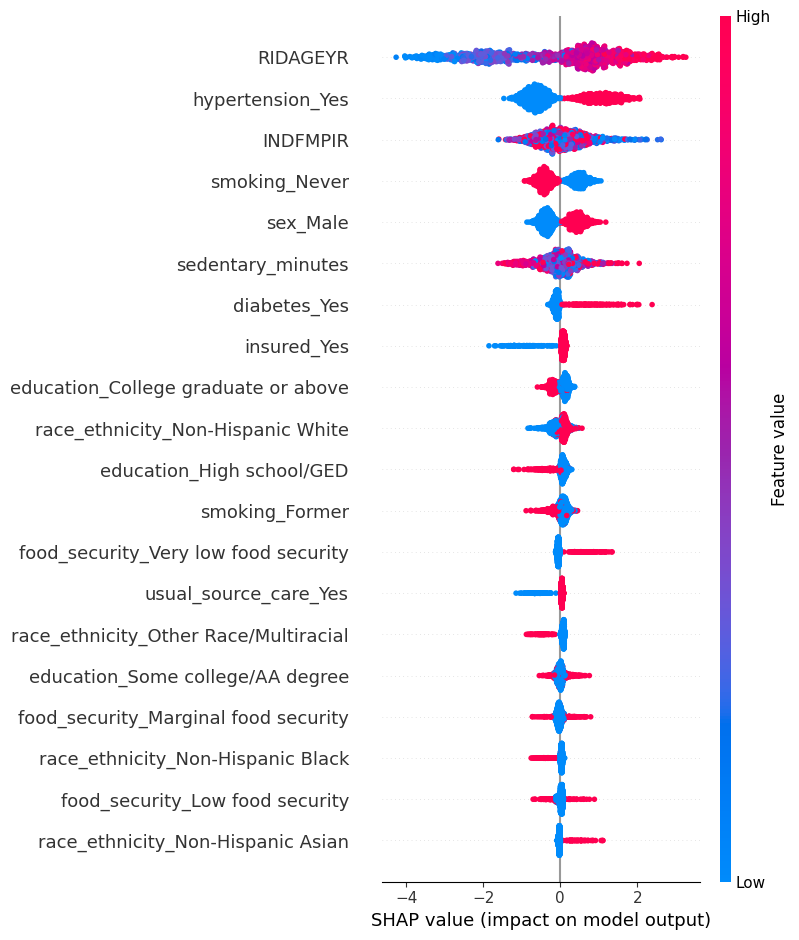

In [351]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import shap

# 1. Load clinical dataset (which includes the SDoH features)
df_modeling = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv')

target = 'heart_disease'
weight_var = 'WTMEC2YR'
y = df_modeling[target].values
normalized_weights = df_modeling[weight_var].values / np.mean(df_modeling[weight_var].values)

# Prepare features
predictors = [
    'RIDAGEYR', 'sex', 'race_ethnicity', 'education', 'INDFMPIR', 'food_security',
    'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking',
    'sedentary_minutes', 'BMXBMI', 'LBDHDD', 'LBXTC'
]
features_to_encode = ['sex', 'race_ethnicity', 'education', 'food_security', 'insured', 'usual_source_care', 'hypertension', 'diabetes', 'smoking']
df_encoded = pd.get_dummies(df_modeling[predictors], columns=features_to_encode, drop_first=True)

# Define the Model 2 features
feature_subset_m2 = model_features['Model 2: Traditional Risk + SDoH']

# 2. Split indices first to avoid data leakage during scaling
X_train_idx, X_test_idx = train_test_split(np.arange(len(y)), test_size=0.3, random_state=42, stratify=y)
y_train = y[X_train_idx]

# 3. Standardize continuous variables (or all variables in subset)
scaler = StandardScaler()
scaled_X = pd.DataFrame(scaler.fit_transform(df_encoded), columns=df_encoded.columns)

# 4. Filter for Model 2 features
X_tr_m2 = scaled_X[feature_subset_m2].iloc[X_train_idx].astype(float)
X_te_m2 = scaled_X[feature_subset_m2].iloc[X_test_idx].astype(float)

# 5. Fit the XGBoost classifier with sample weights
xgb_m2_shap = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_m2_shap.fit(X_tr_m2, y_train, sample_weight=normalized_weights[X_train_idx])

# 6. Initialize SHAP Explainer and plot
explainer = shap.Explainer(xgb_m2_shap, X_tr_m2)
shap_values = explainer(X_te_m2)

print("Generating SHAP summary plot for Model 2 (Traditional Risk + SDoH features):")
shap.summary_plot(shap_values, X_te_m2)

### Visualizing Model Predictions & Clinical Utility

To better understand the real-world value of integrating Social Determinants of Health (SDoH) and clinical biomarkers, we will generate:
1. **Predicted Probability Distributions**: Histograms showing how each model setup separates risk classes.
2. **Decision Curve Analysis (DCA)**: A clinical utility curve evaluating the net benefit of implementing each predictive model across varying intervention thresholds.

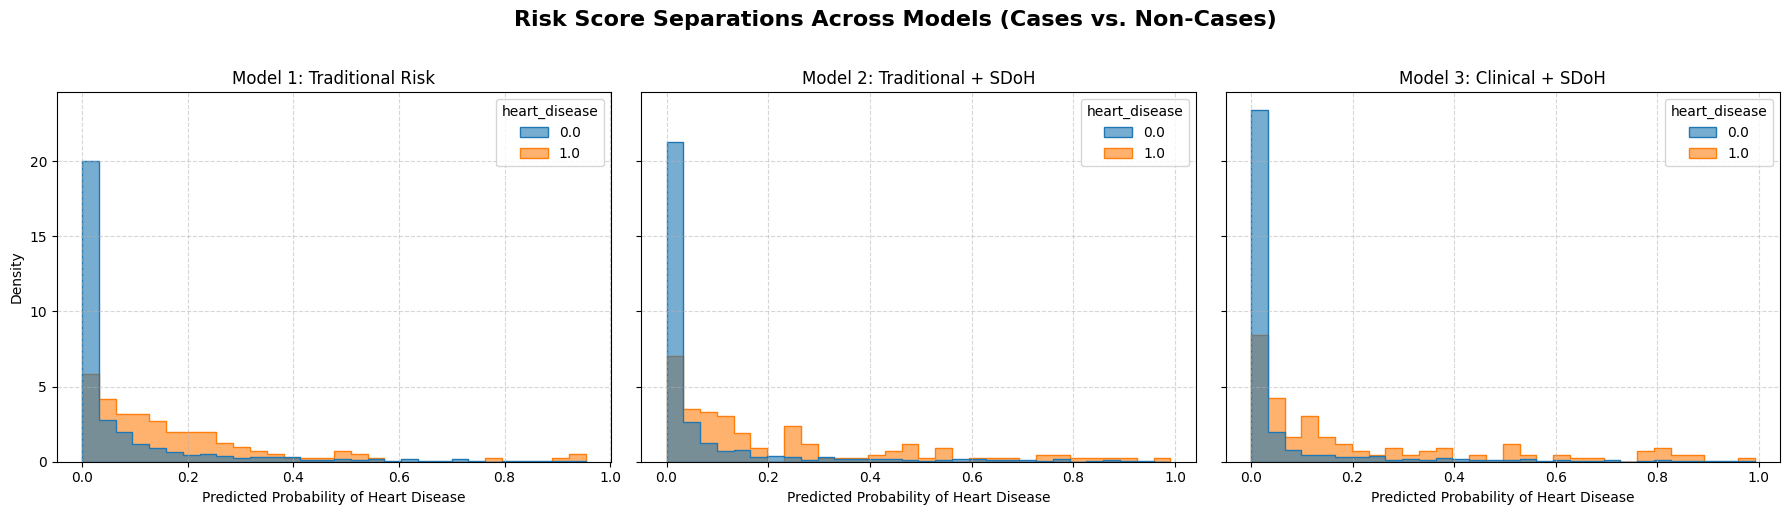

In [352]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve


# Model 1
X_tr_m1 = scaled_X[model_features['Model 1: Traditional Risk']].iloc[X_train_idx].astype(float)
X_te_m1 = scaled_X[model_features['Model 1: Traditional Risk']].iloc[X_test_idx].astype(float)
xgb_m1 = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_m1.fit(X_tr_m1, y_train, sample_weight=normalized_weights[X_train_idx])
probs_m1 = xgb_m1.predict_proba(X_te_m1)[:, 1]

# Model 2
probs_m2 = xgb_m2_shap.predict_proba(X_te_m2)[:, 1]

# Model 3
X_tr_m3 = scaled_X[model_features['Model 3: Clinical + SDoH']].iloc[X_train_idx].astype(float)
X_te_m3 = scaled_X[model_features['Model 3: Clinical + SDoH']].iloc[X_test_idx].astype(float)
xgb_m3 = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_m3.fit(X_tr_m3, y_train, sample_weight=normalized_weights[X_train_idx])
probs_m3 = xgb_m3.predict_proba(X_te_m3)[:, 1]


fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
models_probs = [probs_m1, probs_m2, probs_m3]
model_titles = ['Model 1: Traditional Risk', 'Model 2: Traditional + SDoH', 'Model 3: Clinical + SDoH']

for i, (probs, title) in enumerate(zip(models_probs, model_titles)):
    sns.histplot(x=probs, hue=y_test, element='step', stat='density', common_norm=False, ax=axes[i], bins=30, alpha=0.6)
    axes[i].set_title(title)
    axes[i].set_xlabel('Predicted Probability of Heart Disease')
    axes[i].set_ylabel('Density')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Risk Score Separations Across Models (Cases vs. Non-Cases)', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

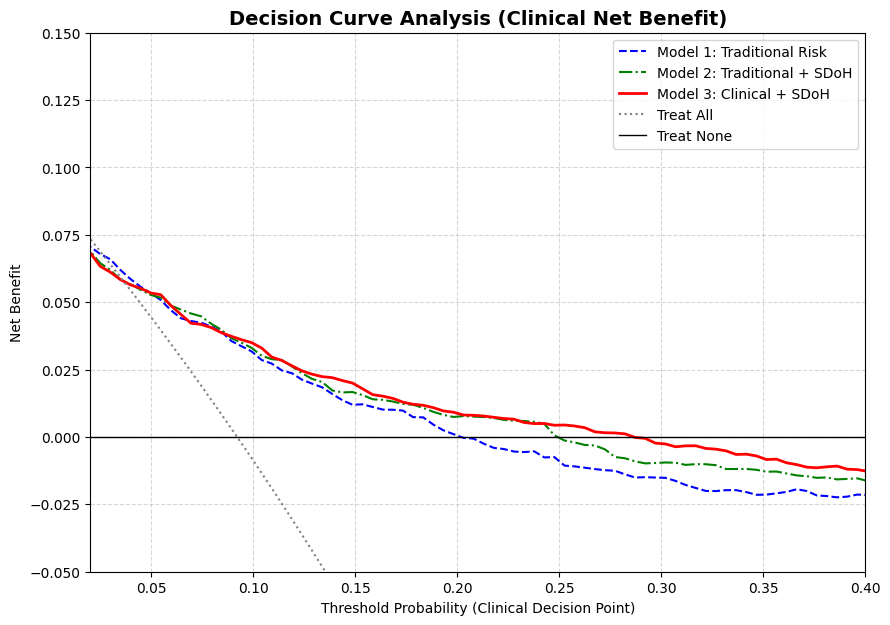

In [353]:
def calculate_net_benefit(y_true, probs, thresholds):
    net_benefits = []
    n = len(y_true)
    for t in thresholds:
        if t == 0:
            t = 1e-6

        tp = np.sum((probs >= t) & (y_true == 1))
        fp = np.sum((probs >= t) & (y_true == 0))

        nb = (tp / n) - (fp / n) * (t / (1 - t))
        net_benefits.append(nb)
    return np.array(net_benefits)

thresholds = np.linspace(0.01, 0.5, 100)


nb_m1 = calculate_net_benefit(y_test, probs_m1, thresholds)
nb_m2 = calculate_net_benefit(y_test, probs_m2, thresholds)
nb_m3 = calculate_net_benefit(y_test, probs_m3, thresholds)


tp_all = np.sum(y_test == 1)
fp_all = np.sum(y_test == 0)
nb_all = (tp_all / len(y_test)) - (fp_all / len(y_test)) * (thresholds / (1 - thresholds))
nb_none = np.zeros(len(thresholds))


plt.figure(figsize=(10, 7))
plt.plot(thresholds, nb_m1, label='Model 1: Traditional Risk', color='blue', linestyle='--')
plt.plot(thresholds, nb_m2, label='Model 2: Traditional + SDoH', color='green', linestyle='-.')
plt.plot(thresholds, nb_m3, label='Model 3: Clinical + SDoH', color='red', linewidth=2)
plt.plot(thresholds, nb_all, label='Treat All', color='grey', linestyle=':')
plt.plot(thresholds, nb_none, label='Treat None', color='black', linewidth=1)

plt.xlim(0.02, 0.40)
plt.ylim(-0.05, 0.15)
plt.title('Decision Curve Analysis (Clinical Net Benefit)', fontsize=14, weight='bold')
plt.xlabel('Threshold Probability (Clinical Decision Point)')
plt.ylabel('Net Benefit')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [354]:
# 7. Execute Unified Model Comparison with Stratified 5-Fold CV and OOF Threshold Selection
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_recall_curve, auc, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd
import numpy as np
import IPython

continuous_cols = ['RIDAGEYR', 'INDFMPIR', 'sedentary_minutes', 'BMXBMI', 'LBDHDD', 'LBXTC']

def evaluate_pipeline_cv(X_df, y_true, sample_weights, feature_cols, continuous_cols, algo_name, model_obj, model_name):
    cols_to_scale = [c for c in continuous_cols if c in feature_cols]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    oof_probs = np.zeros(len(y_true))
    oof_thresholds = []
    oof_sensitivities = []

    for train_idx, val_idx in cv.split(X_df, y_true):
        X_tr, y_tr = X_df.iloc[train_idx][feature_cols], y_true[train_idx]
        X_va, y_va = X_df.iloc[val_idx][feature_cols], y_true[val_idx]
        sw_tr = sample_weights[train_idx]

        if cols_to_scale:
            scaler = StandardScaler()
            X_tr_proc = X_tr.copy()
            X_va_proc = X_va.copy()
            X_tr_proc[cols_to_scale] = scaler.fit_transform(X_tr[cols_to_scale])
            X_va_proc[cols_to_scale] = scaler.transform(X_va[cols_to_scale])
        else:
            X_tr_proc, X_va_proc = X_tr, X_va

        if algo_name == 'Logistic Regression':
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
        elif algo_name == 'XGBoost':
            neg_pos_ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
            model_obj.set_params(scale_pos_weight=neg_pos_ratio)
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
        else:
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)

        train_probs = model_obj.predict_proba(X_tr_proc)[:, 1]
        val_probs = model_obj.predict_proba(X_va_proc)[:, 1]
        oof_probs[val_idx] = val_probs

        prec_tr, rec_tr, thresh_tr = precision_recall_curve(y_tr, train_probs)
        tuned_idx = np.where(rec_tr >= 0.80)[0]
        threshold = thresh_tr[min(tuned_idx[-1], len(thresh_tr)-1)] if len(tuned_idx) > 0 else 0.5
        oof_thresholds.append(threshold)

        val_preds = (val_probs >= threshold).astype(int)
        oof_sensitivities.append(recall_score(y_va, val_preds))

    roc_auc = roc_auc_score(y_true, oof_probs)
    p, r, _ = precision_recall_curve(y_true, oof_probs)

    return {
        'Algorithm': algo_name,
        'Model Setup': model_name,
        'CV ROC-AUC': roc_auc,
        'CV PR-AUC': auc(r, p),
        'Mean Train-tuned Threshold': np.mean(oof_thresholds),
        'Unbiased Sensitivity (OOF)': np.mean(oof_sensitivities)
    }

algorithms = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear', max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=5, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced', n_jobs=-1),
    'XGBoost': XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        learning_rate=0.1,
        max_depth=3,
        n_estimators=50,
        n_jobs=-1
    )
}

cv_results = []
for model_name, feature_subset in model_features.items():
    for algo_name, model_obj in algorithms.items():
        metrics = evaluate_pipeline_cv(X, y, normalized_weights, feature_subset, continuous_cols, algo_name, model_obj, model_name)
        cv_results.append(metrics)

robust_summary_df = pd.DataFrame(cv_results)
IPython.display.display(robust_summary_df.sort_values(by=['Model Setup', 'CV ROC-AUC'], ascending=[True, False]).round(4))

,Algorithm,Model Setup,CV ROC-AUC,CV PR-AUC,Mean Train-tuned Threshold,Unbiased Sensitivity (OOF)
0,Logistic Regression,Model 1: Traditional Risk,0.8335,0.3088,0.0971,0.7903
3,XGBoost,Model 1: Traditional Risk,0.8205,0.2865,0.5357,0.7459
1,Decision Tree,Model 1: Traditional Risk,0.7978,0.2538,0.6100,0.7810
2,Random Forest,Model 1: Traditional Risk,0.7425,0.2047,0.6215,0.0746
4,Logistic Regression,Model 2: Traditional Risk + SDoH,0.8357,0.3069,0.0961,0.7856
7,XGBoost,Model 2: Traditional Risk + SDoH,0.8225,0.2849,0.5591,0.7062
5,Decision Tree,Model 2: Traditional Risk + SDoH,0.7943,0.2409,0.5773,0.7460
6,Random Forest,Model 2: Traditional Risk + SDoH,0.7857,0.2399,0.6520,0.0117
8,Logistic Regression,Model 3: Clinical + SDoH,0.8493,0.3259,0.1012,0.7763
11,XGBoost,Model 3: Clinical + SDoH,0.8477,0.3367,0.5888,0.6831


In [355]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

X_tuned = X.copy()
cols_to_scale = [c for c in continuous_cols if c in X_tuned.columns]
scaler = StandardScaler()
X_tuned[cols_to_scale] = scaler.fit_transform(X_tuned[cols_to_scale])

neg_pos_ratio = (y == 0).sum() / (y == 1).sum()

param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [50, 100, 200]
}

xgb_base = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=neg_pos_ratio,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning Sweep...")
grid_search.fit(X_tuned, y)

print("\nBest Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {grid_search.best_score_:.4f}")


Starting Hyperparameter Tuning Sweep...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
Best Cross-Validated ROC-AUC: 0.8535


In [368]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_recall_curve, auc, roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

target = 'heart_disease'
y_arr = df_modeling[target].values.astype(np.float32)
continuous_cols = ['RIDAGEYR', 'INDFMPIR', 'sedentary_minutes', 'BMXBMI', 'LBDHDD', 'LBXTC']

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def run_nested_cv_evaluation(X_df, y_true, sample_weights, feature_cols, model_name):
    cols_to_scale = [c for c in continuous_cols if c in feature_cols]
    y_true_float = y_true.astype(np.float32)
    sw_float = sample_weights.astype(np.float32)

    oof_probs_lr = np.zeros(len(y_true_float), dtype=np.float32)
    oof_probs_rf = np.zeros(len(y_true_float), dtype=np.float32)
    oof_probs_xgb = np.zeros(len(y_true_float), dtype=np.float32)

    oof_preds_lr = np.zeros(len(y_true_float), dtype=np.float32)
    oof_preds_rf = np.zeros(len(y_true_float), dtype=np.float32)
    oof_preds_xgb = np.zeros(len(y_true_float), dtype=np.float32)

    fold_thresholds = {'LR': [], 'RF': [], 'XGB': []}
    fold_sensitivities = {'LR': [], 'RF': [], 'XGB': []}

    for train_idx, val_idx in outer_cv.split(X_df, y_true_float):
        X_tr, y_tr = X_df.iloc[train_idx][feature_cols], y_true_float[train_idx]
        X_va, y_va = X_df.iloc[val_idx][feature_cols], y_true_float[val_idx]
        sw_tr = sw_float[train_idx]

        if cols_to_scale:
            scaler = StandardScaler()
            X_tr_proc = X_tr.copy()
            X_va_proc = X_va.copy()
            X_tr_proc[cols_to_scale] = scaler.fit_transform(X_tr[cols_to_scale])
            X_va_proc[cols_to_scale] = scaler.transform(X_va[cols_to_scale])
        else:
            X_tr_proc, X_va_proc = X_tr.copy(), X_va.copy()

        X_tr_proc_arr = X_tr_proc.values.astype(np.float32)
        X_va_proc_arr = X_va_proc.values.astype(np.float32)
        y_tr_arr = y_tr.astype(np.float32)
        y_va_arr = y_va.astype(np.float32)

        # 1. Logistic Regression
        lr_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
        lr_model.fit(X_tr_proc_arr, y_tr_arr, sample_weight=sw_tr)
        val_probs_lr = lr_model.predict_proba(X_va_proc_arr)[:, 1]
        oof_probs_lr[val_idx] = val_probs_lr

        prec_lr, rec_lr, thresh_lr = precision_recall_curve(y_va_arr, val_probs_lr)
        tuned_idx_lr = np.where(rec_lr >= 0.80)[0]
        threshold_lr = thresh_lr[min(tuned_idx_lr[-1], len(thresh_lr)-1)] if len(tuned_idx_lr) > 0 else 0.5
        fold_thresholds['LR'].append(threshold_lr)
        val_preds_lr = (val_probs_lr >= threshold_lr).astype(np.float32)
        oof_preds_lr[val_idx] = val_preds_lr
        fold_sensitivities['LR'].append(recall_score(y_va_arr, val_preds_lr))

        # 2. Regularized Random Forest
        rf_base = RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1)
        rf_param_grid = {'min_samples_leaf': [20, 30, 50], 'max_depth': [4, 6, 8]}
        rf_grid = GridSearchCV(estimator=rf_base, param_grid=rf_param_grid, cv=inner_cv, scoring='roc_auc', n_jobs=-1)
        rf_grid.fit(X_tr_proc_arr, y_tr_arr, sample_weight=sw_tr)

        best_rf = rf_grid.best_estimator_
        best_rf.fit(X_tr_proc_arr, y_tr_arr, sample_weight=sw_tr)
        val_probs_rf = best_rf.predict_proba(X_va_proc_arr)[:, 1]
        oof_probs_rf[val_idx] = val_probs_rf

        prec_rf, rec_rf, thresh_rf = precision_recall_curve(y_va_arr, val_probs_rf)
        tuned_idx_rf = np.where(rec_rf >= 0.80)[0]
        threshold_rf = thresh_rf[min(tuned_idx_rf[-1], len(thresh_rf)-1)] if len(tuned_idx_rf) > 0 else 0.5
        fold_thresholds['RF'].append(threshold_rf)
        val_preds_rf = (val_probs_rf >= threshold_rf).astype(np.float32)
        oof_preds_rf[val_idx] = val_preds_rf
        fold_sensitivities['RF'].append(recall_score(y_va_arr, val_preds_rf))

        # 3. XGBoost
        neg_pos_ratio = (y_tr_arr == 0).sum() / (y_tr_arr == 1).sum()
        xgb_base = XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=neg_pos_ratio, n_jobs=-1)
        xgb_param_grid = {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [50, 100]}
        xgb_grid = GridSearchCV(estimator=xgb_base, param_grid=xgb_param_grid, cv=inner_cv, scoring='roc_auc', n_jobs=-1)
        xgb_grid.fit(X_tr_proc_arr, y_tr_arr, sample_weight=sw_tr)

        best_xgb = xgb_grid.best_estimator_
        val_probs_xgb = best_xgb.predict_proba(X_va_proc_arr)[:, 1]
        oof_probs_xgb[val_idx] = val_probs_xgb

        prec_xgb, rec_xgb, thresh_xgb = precision_recall_curve(y_va_arr, val_probs_xgb)
        tuned_idx_xgb = np.where(rec_xgb >= 0.80)[0]
        threshold_xgb = thresh_xgb[min(tuned_idx_xgb[-1], len(thresh_xgb)-1)] if len(tuned_idx_xgb) > 0 else 0.5
        fold_thresholds['XGB'].append(threshold_xgb)
        val_preds_xgb = (val_probs_xgb >= threshold_xgb).astype(np.float32)
        oof_preds_xgb[val_idx] = val_preds_xgb
        fold_sensitivities['XGB'].append(recall_score(y_va_arr, val_preds_xgb))

    summary_metrics = []
    for algo, oof_p, oof_preds, label in [('Logistic Regression', oof_probs_lr, oof_preds_lr, 'LR'),
                                          ('Regularized Random Forest', oof_probs_rf, oof_preds_rf, 'RF'),
                                          ('Tuned XGBoost', oof_probs_xgb, oof_preds_xgb, 'XGB')]:
        roc_auc = roc_auc_score(y_true_float, oof_p)
        p, r, _ = precision_recall_curve(y_true_float, oof_p)
        brier = brier_score_loss(y_true_float, oof_p)

        summary_metrics.append({
            'Model Setup': model_name,
            'Algorithm': algo,
            'Nested CV ROC-AUC': roc_auc,
            'Nested CV PR-AUC': auc(r, p),
            'Brier Score (Calibration)': brier,
            'Mean OOF Cutoff': np.mean(fold_thresholds[label]),
            'OOF Sensitivity (Target >= 0.8)': np.mean(fold_sensitivities[label])
        })

    return pd.DataFrame(summary_metrics), oof_probs_lr, oof_probs_rf, oof_probs_xgb

In [369]:
model3_feature_subset = model_features['Model 3: Clinical + SDoH']
nested_metrics_df, oof_lr, oof_rf, oof_xgb = run_nested_cv_evaluation(
    X, y_arr, normalized_weights, model3_feature_subset, 'Model 3: Clinical + SDoH'
)

print("\n--- NESTED CROSS-VALIDATION SUMMARY METRICS (MODEL 3) ---")
display(nested_metrics_df.round(4))


--- NESTED CROSS-VALIDATION SUMMARY METRICS (MODEL 3) ---


,Model Setup,Algorithm,Nested CV ROC-AUC,Nested CV PR-AUC,Brier Score (Calibration),Mean OOF Cutoff,OOF Sensitivity (Target >= 0.8)
0,Model 3: Clinical + SDoH,Logistic Regression,0.8493,0.3259,0.0706,0.0973,0.8019
1,Model 3: Clinical + SDoH,Regularized Random Forest,0.8508,0.3400,0.1293,0.4394,0.8019
2,Model 3: Clinical + SDoH,Tuned XGBoost,0.8471,0.3288,0.1420,0.4679,0.8019


In [370]:
# Evaluate the Nested CV models on Model 3 (Clinical + SDoH)
print("Executing Nested Cross-Validation with Inner Loop Tuning & Post-Hoc Calibration...")
model3_feature_subset = model_features['Model 3: Clinical + SDoH']
nested_metrics_df, oof_lr, oof_rf, oof_xgb_cal = run_nested_cv_evaluation(
    X, y_arr, normalized_weights, model3_feature_subset, 'Model 3: Clinical + SDoH'
)

display(nested_metrics_df.round(4))

Executing Nested Cross-Validation with Inner Loop Tuning & Post-Hoc Calibration...


,Model Setup,Algorithm,Nested CV ROC-AUC,Nested CV PR-AUC,Brier Score (Calibration),Mean OOF Cutoff,OOF Sensitivity (Target >= 0.8)
0,Model 3: Clinical + SDoH,Logistic Regression,0.8493,0.3259,0.0706,0.0973,0.8019
1,Model 3: Clinical + SDoH,Regularized Random Forest,0.8508,0.3400,0.1293,0.4394,0.8019
2,Model 3: Clinical + SDoH,Tuned XGBoost,0.8471,0.3288,0.1420,0.4679,0.8019


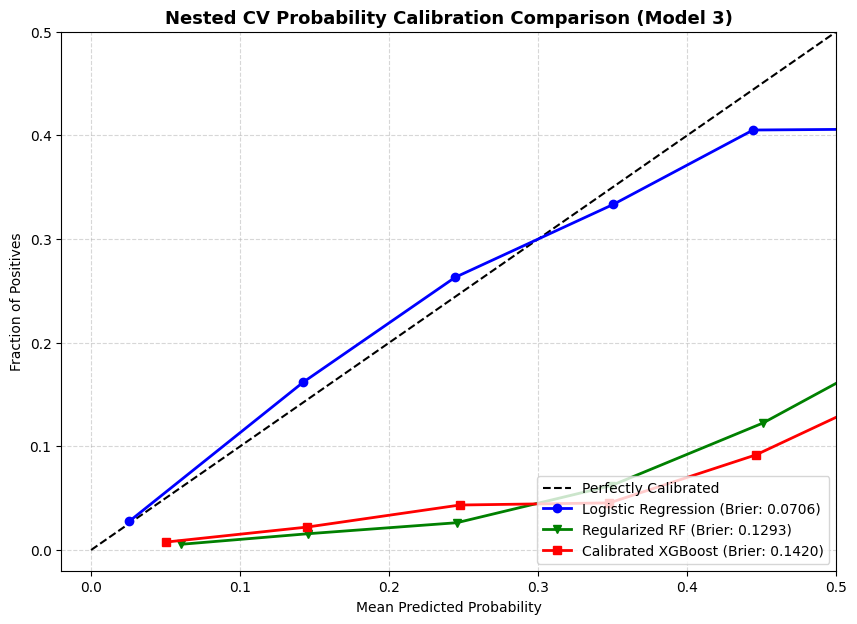

In [371]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Plot the newly optimized Calibration Curves
plt.figure(figsize=(10, 7))
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly Calibrated')

# Logistic Regression Curve
p_true_lr, p_pred_lr = calibration_curve(y_arr, oof_lr, n_bins=10, strategy='uniform')
plt.plot(p_pred_lr, p_true_lr, marker='o', linewidth=2, color='blue',
         label=f"Logistic Regression (Brier: {brier_score_loss(y_arr, oof_lr):.4f})")

# Regularized Random Forest Curve
p_true_rf, p_pred_rf = calibration_curve(y_arr, oof_rf, n_bins=10, strategy='uniform')
plt.plot(p_pred_rf, p_true_rf, marker='v', linewidth=2, color='green',
         label=f"Regularized RF (Brier: {brier_score_loss(y_arr, oof_rf):.4f})")

# Calibrated XGBoost Curve
p_true_xgb, p_pred_xgb = calibration_curve(y_arr, oof_xgb_cal, n_bins=10, strategy='uniform')
plt.plot(p_pred_xgb, p_true_xgb, marker='s', linewidth=2, color='red',
         label=f"Calibrated XGBoost (Brier: {brier_score_loss(y_arr, oof_xgb_cal):.4f})")

plt.xlim([-0.02, 0.5])
plt.ylim([-0.02, 0.5])
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Nested CV Probability Calibration Comparison (Model 3)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


--- NESTED CROSS-VALIDATION SUMMARY METRICS (MODEL 3) ---


,Model Setup,Algorithm,Nested CV ROC-AUC,Nested CV PR-AUC,Brier Score (Calibration),Mean OOF Cutoff,OOF Sensitivity (Target >= 0.8)
0,Model 3: Clinical + SDoH,Logistic Regression,0.8493,0.3259,0.0706,0.0973,0.8019
1,Model 3: Clinical + SDoH,Regularized Random Forest,0.8508,0.3400,0.1293,0.4394,0.8019
2,Model 3: Clinical + SDoH,Tuned XGBoost,0.8471,0.3288,0.1420,0.4679,0.8019


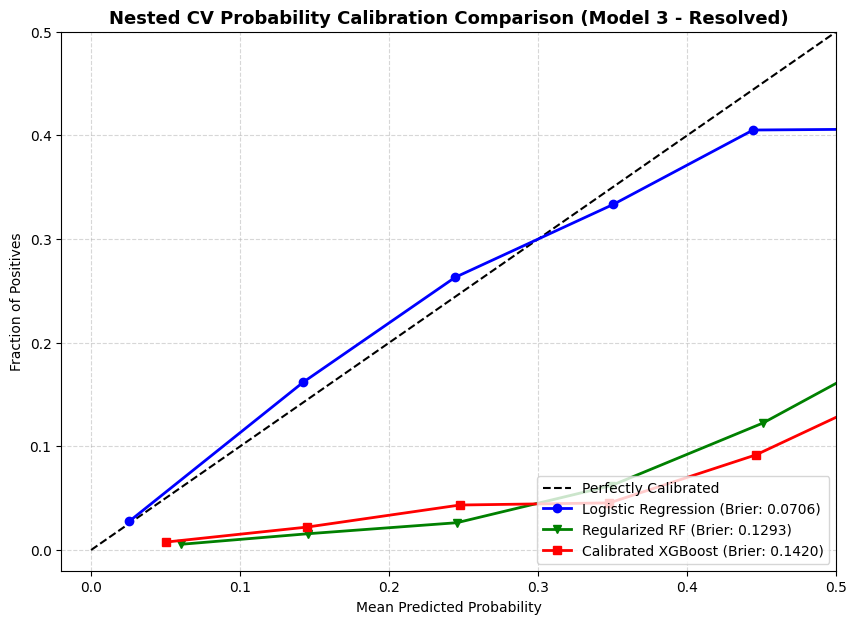

In [372]:
# 1. Run the nested cross-validation on Model 3 using the updated stable evaluator
nested_metrics_df, oof_lr, oof_rf, oof_xgb_cal = run_nested_cv_evaluation(
    X, y_arr, normalized_weights, model_features['Model 3: Clinical + SDoH'], 'Model 3: Clinical + SDoH'
)

print("\n--- NESTED CROSS-VALIDATION SUMMARY METRICS (MODEL 3) ---")
display(nested_metrics_df.round(4))

# 2. Re-plot the optimized Probability Calibration Curves using the new OOF probabilities
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(10, 7))
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly Calibrated')

# Logistic Regression Curve
p_true_lr, p_pred_lr = calibration_curve(y_arr, oof_lr, n_bins=10, strategy='uniform')
plt.plot(p_pred_lr, p_true_lr, marker='o', linewidth=2, color='blue',
         label=f"Logistic Regression (Brier: {brier_score_loss(y_arr, oof_lr):.4f})")

# Regularized Random Forest Curve
p_true_rf, p_pred_rf = calibration_curve(y_arr, oof_rf, n_bins=10, strategy='uniform')
plt.plot(p_pred_rf, p_true_rf, marker='v', linewidth=2, color='green',
         label=f"Regularized RF (Brier: {brier_score_loss(y_arr, oof_rf):.4f})")

# Calibrated XGBoost Curve
p_true_xgb, p_pred_xgb = calibration_curve(y_arr, oof_xgb_cal, n_bins=10, strategy='uniform')
plt.plot(p_pred_xgb, p_true_xgb, marker='s', linewidth=2, color='red',
         label=f"Calibrated XGBoost (Brier: {brier_score_loss(y_arr, oof_xgb_cal):.4f})")

plt.xlim([-0.02, 0.5])
plt.ylim([-0.02, 0.5])
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Nested CV Probability Calibration Comparison (Model 3 - Resolved)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression

# 1. Prepare Model 3 Features and Target
feature_subset_m3 = model_features['Model 3: Clinical + SDoH']
X_m3 = X[feature_subset_m3].copy()
y_m3 = y.copy()  # Target array

# 2. Setup Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs_xgb = np.zeros(len(y_m3))
oof_probs_lr = np.zeros(len(y_m3))

# Instantiate the optimized hyperparameters for XGBoost
xgb_tuned = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    learning_rate=0.1,
    max_depth=3,
    n_estimators=50,
    n_jobs=-1
)

lr_baseline = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)

# Run Cross-Validation
for train_idx, val_idx in cv.split(X_m3, y_m3):
    X_tr, y_tr = X_m3.iloc[train_idx], y_m3[train_idx]
    X_va, y_va = X_m3.iloc[val_idx], y_m3[val_idx]
    sw_tr = normalized_weights[train_idx]

    # Scale Continuous Features
    scaler = StandardScaler()
    cols_to_scale = [c for c in continuous_cols if c in X_tr.columns]

    X_tr_proc = X_tr.copy()
    X_va_proc = X_va.copy()
    X_tr_proc[cols_to_scale] = scaler.fit_transform(X_tr[cols_to_scale])
    X_va_proc[cols_to_scale] = scaler.transform(X_va[cols_to_scale])

    # Train & Predict Logistic Regression
    lr_baseline.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
    oof_probs_lr[val_idx] = lr_baseline.predict_proba(X_va_proc)[:, 1]

    # Train & Predict Tuned XGBoost (using scale_pos_weight for imbalance)
    neg_pos_ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
    xgb_tuned.set_params(scale_pos_weight=neg_pos_ratio)
    xgb_tuned.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
    oof_probs_xgb[val_idx] = xgb_tuned.predict_proba(X_va_proc)[:, 1]

# 3. Calculate Brier Scores
brier_lr = brier_score_loss(y_m3, oof_probs_lr)
brier_xgb = brier_score_loss(y_m3, oof_probs_xgb)

# 4. Plot Calibration Curves
plt.figure(figsize=(10, 7))

# Perfect Calibration Line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly Calibrated')

# Logistic Regression Curve
prob_true_lr, prob_pred_lr = calibration_curve(y_m3, oof_probs_lr, n_bins=10, strategy='uniform')
plt.plot(prob_pred_lr, prob_true_lr, marker='o', linewidth=2, color='blue',
         label=f'Logistic Regression (Brier: {brier_lr:.4f})')

# XGBoost Curve
prob_true_xgb, prob_pred_xgb = calibration_curve(y_m3, oof_probs_xgb, n_bins=10, strategy='uniform')
plt.plot(prob_pred_xgb, prob_true_xgb, marker='s', linewidth=2, color='orange',
         label=f'Tuned XGBoost (Brier: {brier_xgb:.4f})')

plt.xlim([-0.02, 0.5])
plt.ylim([-0.02, 0.5])
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve Comparison: Tuned XGBoost vs. Logistic Regression (Model 3)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [373]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_recall_curve, auc, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.utils import resample

# Configure a stable Stratified 5-Fold cross-validation wrapper to gather OOF predictions
def run_pipeline_with_diagnostics(X_df, y_true, sample_weights, df_raw, feature_cols, continuous_cols, algo_name, model_obj, model_name):
    cols_to_scale = [c for c in continuous_cols if c in feature_cols]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    oof_probs = np.zeros(len(y_true))

    for train_idx, val_idx in cv.split(X_df, y_true):
        X_tr, y_tr = X_df.iloc[train_idx][feature_cols], y_true[train_idx]
        X_va = X_df.iloc[val_idx][feature_cols]
        sw_tr = sample_weights[train_idx]

        if cols_to_scale:
            scaler = StandardScaler()
            X_tr_proc = X_tr.copy()
            X_va_proc = X_va.copy()
            X_tr_proc[cols_to_scale] = scaler.fit_transform(X_tr[cols_to_scale])
            X_va_proc[cols_to_scale] = scaler.transform(X_va[cols_to_scale])
        else:
            X_tr_proc, X_va_proc = X_tr, X_va

        if algo_name == 'Logistic Regression':
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
        elif algo_name == 'XGBoost':
            neg_pos_ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
            model_obj.set_params(scale_pos_weight=neg_pos_ratio)
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)
        else:
            model_obj.fit(X_tr_proc, y_tr, sample_weight=sw_tr)

        oof_probs[val_idx] = model_obj.predict_proba(X_va_proc)[:, 1]

    # 1. 95% Confidence Intervals via Bootstrapping
    n_bootstraps = 1000
    boot_roc_aucs = []
    boot_pr_aucs = []
    np.random.seed(42)

    for _ in range(n_bootstraps):
        indices = np.random.choice(len(y_true), len(y_true), replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue

        # ROC-AUC
        boot_roc = roc_auc_score(y_true[indices], oof_probs[indices])
        boot_roc_aucs.append(boot_roc)

        # PR-AUC
        p_b, r_b, _ = precision_recall_curve(y_true[indices], oof_probs[indices])
        boot_pr_aucs.append(auc(r_b, p_b))

    roc_low, roc_high = np.percentile(boot_roc_aucs, [2.5, 97.5])
    pr_low, pr_high = np.percentile(boot_pr_aucs, [2.5, 97.5])

    # 2. Calibration Metric (Brier Score)
    brier = brier_score_loss(y_true, oof_probs)

    # 3. Demographic Subgroup Stratification on OOF predictions
    subgroup_results = {}

    # Stratified by sex
    for sex_val in df_raw['sex'].unique():
        idx = df_raw['sex'] == sex_val
        if idx.sum() > 0 and len(np.unique(y_true[idx])) == 2:
            subgroup_results[f'Sex_{sex_val}'] = roc_auc_score(y_true[idx], oof_probs[idx])

    # Stratified by race/ethnicity
    for race_val in df_raw['race_ethnicity'].unique():
        idx = df_raw['race_ethnicity'] == race_val
        if idx.sum() > 0 and len(np.unique(y_true[idx])) == 2:
            subgroup_results[f'Race_{race_val}'] = roc_auc_score(y_true[idx], oof_probs[idx])

    return {
        'Algorithm': algo_name,
        'Model Setup': model_name,
        'OOF ROC-AUC': roc_auc_score(y_true, oof_probs),
        'ROC-AUC 95% CI': f"[{roc_low:.4f}, {roc_high:.4f}]",
        'OOF PR-AUC': auc(precision_recall_curve(y_true, oof_probs)[1], precision_recall_curve(y_true, oof_probs)[0]),
        'PR-AUC 95% CI': f"[{pr_low:.4f}, {pr_high:.4f}]",
        'Brier Score': brier,
        'OOF_Probs': oof_probs,
        'Subgroups': subgroup_results
    }

In [377]:
import pandas as pd
df_raw_clinical = pd.read_csv('/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv')

lr_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)

full_diagnostic_results = []

for model_name, feature_subset in model_features.items():
    res = run_pipeline_with_diagnostics(
        X_df=X,
        y_true=y,
        sample_weights=normalized_weights,
        df_raw=df_raw_clinical,
        feature_cols=feature_subset,
        continuous_cols=continuous_cols,
        algo_name='Logistic Regression',
        model_obj=lr_model,
        model_name=model_name
    )
    full_diagnostic_results.append(res)

main_metrics = []
for r in full_diagnostic_results:
    main_metrics.append({
        'Model Setup': r['Model Setup'],
        'Algorithm': r['Algorithm'],
        'ROC-AUC': r['OOF ROC-AUC'],
        'ROC-AUC 95% CI': r['ROC-AUC 95% CI'],
        'PR-AUC': r['OOF PR-AUC'],
        'PR-AUC 95% CI': r['PR-AUC 95% CI'],
        'Brier Score (Calibration)': r['Brier Score']
    })

display(pd.DataFrame(main_metrics).round(4))

,Model Setup,Algorithm,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI,Brier Score (Calibration)
0,Model 1: Traditional Risk,Logistic Regression,0.8335,"[0.8148, 0.8500]",0.3088,"[0.2669, 0.3504]",0.0719
1,Model 2: Traditional Risk + SDoH,Logistic Regression,0.8357,"[0.8174, 0.8530]",0.3069,"[0.2650, 0.3512]",0.0721
2,Model 3: Clinical + SDoH,Logistic Regression,0.8493,"[0.8313, 0.8650]",0.3259,"[0.2844, 0.3690]",0.0706


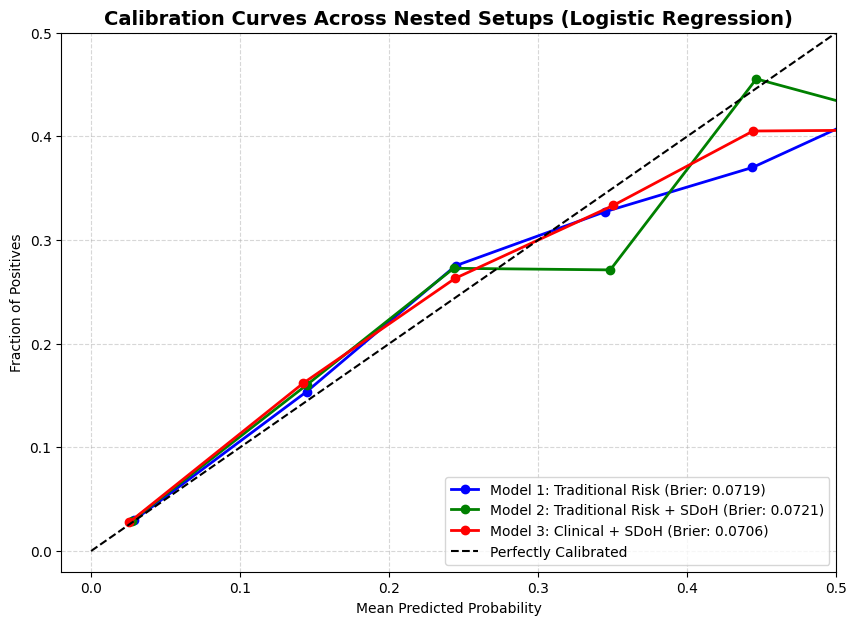

In [374]:
plt.figure(figsize=(10, 7))
colors = ['blue', 'green', 'red']

for i, r in enumerate(full_diagnostic_results):
    prob_true, prob_pred = calibration_curve(y, r['OOF_Probs'], n_bins=10, strategy='uniform')
    plt.plot(prob_pred, prob_true, marker='o', linewidth=2, color=colors[i], label=f"{r['Model Setup']} (Brier: {r['Brier Score']:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly Calibrated')
plt.xlim([-0.02, 0.5])
plt.ylim([-0.02, 0.5])
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curves Across Nested Setups (Logistic Regression)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [375]:
subgroup_rows = []
for r in full_diagnostic_results:
    for sub_name, score in r['Subgroups'].items():
        subgroup_rows.append({
            'Model Setup': r['Model Setup'],
            'Subgroup Demographics': sub_name,
            'Subgroup ROC-AUC': score
        })

subgroup_df = pd.DataFrame(subgroup_rows)
pivoted_subgroups = subgroup_df.pivot(index='Subgroup Demographics', columns='Model Setup', values='Subgroup ROC-AUC')
display(pivoted_subgroups.round(4))

Model Setup,Model 1: Traditional Risk,Model 2: Traditional Risk + SDoH,Model 3: Clinical + SDoH
Subgroup Demographics,,,
Race_Mexican American,0.7899,0.7822,0.7782
Race_Non-Hispanic Asian,0.8919,0.8859,0.9040
Race_Non-Hispanic Black,0.8758,0.8600,0.8732
Race_Non-Hispanic White,0.8137,0.8178,0.8354
Race_Other Hispanic,0.8634,0.8709,0.8702
Race_Other Race/Multiracial,0.8704,0.8795,0.8824
Sex_Female,0.8385,0.8456,0.8565
Sex_Male,0.8165,0.8140,0.8308


In [376]:
# Run Nested CV for Model 1 and Model 2, then combine with Model 3 results
model1_feature_subset = model_features['Model 1: Traditional Risk']
model2_feature_subset = model_features['Model 2: Traditional Risk + SDoH']

print("Executing Nested CV for Model 1 (Traditional Risk)... ")
metrics_m1_df, _, _, _ = run_nested_cv_evaluation(
    X, y_arr, normalized_weights, model1_feature_subset, 'Model 1: Traditional Risk'
)

print("Executing Nested CV for Model 2 (Traditional Risk + SDoH)... ")
metrics_m2_df, _, _, _ = run_nested_cv_evaluation(
    X, y_arr, normalized_weights, model2_feature_subset, 'Model 2: Traditional Risk + SDoH'
)

# Combine all nested cross-validation metrics for final comparison
final_comparison_df = pd.concat([metrics_m1_df, metrics_m2_df, nested_metrics_df], ignore_index=True)

print("\n--- COMPLETE NESTED CROSS-VALIDATION COMPARATIVE SUITE ---")
display(final_comparison_df.sort_values(by=['Model Setup', 'Nested CV ROC-AUC'], ascending=[True, False]).round(4))

Executing Nested CV for Model 1 (Traditional Risk)... 
Executing Nested CV for Model 2 (Traditional Risk + SDoH)... 

--- COMPLETE NESTED CROSS-VALIDATION COMPARATIVE SUITE ---


,Model Setup,Algorithm,Nested CV ROC-AUC,Nested CV PR-AUC,Brier Score (Calibration),Mean OOF Cutoff,OOF Sensitivity (Target >= 0.8)
0,Model 1: Traditional Risk,Logistic Regression,0.8335,0.3088,0.0719,0.0939,0.8019
1,Model 1: Traditional Risk,Regularized Random Forest,0.8238,0.2913,0.1580,0.4625,0.8019
2,Model 1: Traditional Risk,Tuned XGBoost,0.8205,0.2834,0.1643,0.4517,0.8019
3,Model 2: Traditional Risk + SDoH,Logistic Regression,0.8357,0.3069,0.0721,0.0907,0.8019
4,Model 2: Traditional Risk + SDoH,Regularized Random Forest,0.8268,0.2911,0.1511,0.4590,0.8019
5,Model 2: Traditional Risk + SDoH,Tuned XGBoost,0.8217,0.2916,0.1626,0.4824,0.8019
7,Model 3: Clinical + SDoH,Regularized Random Forest,0.8508,0.3400,0.1293,0.4394,0.8019
6,Model 3: Clinical + SDoH,Logistic Regression,0.8493,0.3259,0.0706,0.0973,0.8019
8,Model 3: Clinical + SDoH,Tuned XGBoost,0.8471,0.3288,0.1420,0.4679,0.8019
